In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
)

from nba_archetypes.config import (
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
)

players = pd.read_parquet(
    PROCESSED_DATA_DIR / "player_style_features.parquet"
).reset_index(drop=True)

offensive_dimensions = [
    "BALL_DOMINANCE",
    "PLAYMAKING",
    "BALL_MOVEMENT",
    "RIM_PRESSURE",
    "ON_BALL_CREATION",
    "PERIMETER_SHOOTING",
    "INTERIOR_OFFENSE",
    "OFFENSIVE_REBOUNDING",
]

offense_cols = [
    f"{name}_SCORE"
    for name in offensive_dimensions
]

X = players[offense_cols].to_numpy()

assert players["PLAYER_ID"].is_unique
assert len(offense_cols) == 8
assert np.isfinite(X).all()

print("Players:", len(players))
print("Offensive dimensions:", X.shape[1])

Players: 450
Offensive dimensions: 8


,PC,Explained Variance,Cumulative Variance
0,1,0.440,0.440
1,2,0.263,0.702
2,3,0.135,0.837
3,4,0.066,0.904
4,5,0.044,0.948
5,6,0.032,0.980
6,7,0.015,0.994
7,8,0.006,1.000


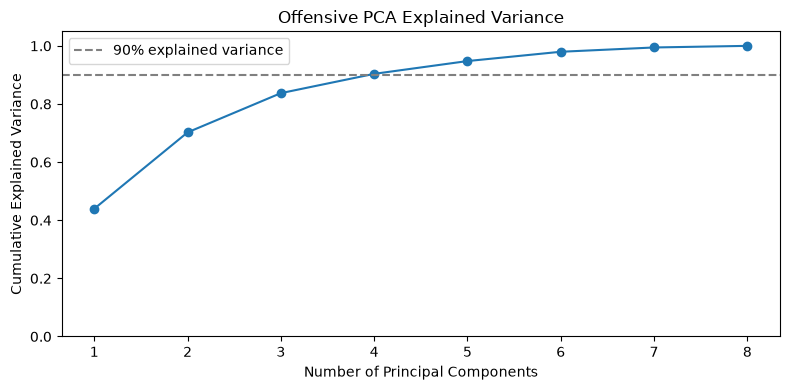

In [4]:
pca = PCA()
pca.fit(X)

pca_summary = pd.DataFrame({
    "PC": range(1, X.shape[1] + 1),
    "Explained Variance": pca.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(
        pca.explained_variance_ratio_
    ),
})

display(pca_summary.round(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    pca_summary["PC"],
    pca_summary["Cumulative Variance"],
    marker="o",
)

ax.axhline(
    0.90,
    linestyle="--",
    color="gray",
    label="90% explained variance",
)

ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("Offensive PCA Explained Variance")
ax.set_xticks(range(1, 9))
ax.set_ylim(0, 1.05)
ax.legend()

plt.tight_layout()
plt.show()

In [5]:
# PCA representations.
X_pca3 = PCA(n_components=3).fit_transform(X)
X_pca4 = PCA(n_components=4).fit_transform(X)

K_VALUES = range(2, 11)

results = []
fitted_models = {}


for k in range(1, 11):

    # Gaussian Mixture Models also support k=1.
    configurations = [
        (
            "GMM diagonal",
            GaussianMixture(
                n_components=k,
                covariance_type="diag",
                reg_covar=1e-4,
                n_init=3,
                random_state=42,
            ),
            X,
        ),
        (
            "GMM full",
            GaussianMixture(
                n_components=k,
                covariance_type="full",
                reg_covar=1e-4,
                n_init=3,
                random_state=42,
            ),
            X,
        ),
    ]

    if k >= 2:
        configurations += [
            (
                "KMeans",
                KMeans(
                    n_clusters=k,
                    n_init=20,
                    random_state=42,
                ),
                X,
            ),
            (
                "KMeans PCA3",
                KMeans(
                    n_clusters=k,
                    n_init=20,
                    random_state=42,
                ),
                X_pca3,
            ),
            (
                "KMeans PCA4",
                KMeans(
                    n_clusters=k,
                    n_init=20,
                    random_state=42,
                ),
                X_pca4,
            ),
            (
                "Agglomerative Ward",
                AgglomerativeClustering(
                    n_clusters=k,
                    linkage="ward",
                ),
                X,
            ),
            (
                "Agglomerative Cosine",
                AgglomerativeClustering(
                    n_clusters=k,
                    linkage="average",
                    metric="cosine",
                ),
                X,
            ),
        ]

    for name, model, X_model in configurations:

        # Fit the model and obtain cluster assignments.
        if isinstance(model, GaussianMixture):
            model.fit(X_model)
            labels = model.predict(X_model)
            bic = model.bic(X_model)
            aic = model.aic(X_model)
        else:
            labels = model.fit_predict(X_model)
            bic = np.nan
            aic = np.nan

        n_groups = len(np.unique(labels))
        sizes = pd.Series(labels).value_counts()

        # k=1 cannot be evaluated with silhouette, DB, or CH.
        if 2 <= n_groups < len(X):
            # All models are evaluated in the original
            # eight-dimensional space for comparability.
            silhouette_euclidean = silhouette_score(
                X, labels, metric="euclidean"
            )

            silhouette_cosine = silhouette_score(
                X, labels, metric="cosine"
            )

            db = davies_bouldin_score(X, labels)
            ch = calinski_harabasz_score(X, labels)

        else:
            silhouette_euclidean = np.nan
            silhouette_cosine = np.nan
            db = np.nan
            ch = np.nan

        results.append({
            "Model": name,
            "k": k,
            "Actual groups": n_groups,
            "Silhouette Euclidean": silhouette_euclidean,
            "Silhouette Cosine": silhouette_cosine,
            "Davies-Bouldin": db,
            "Calinski-Harabasz": ch,
            "BIC": bic,
            "AIC": aic,
            "Inertia": getattr(model, "inertia_", np.nan),
            "Smallest cluster": sizes.min(),
            "Largest cluster": sizes.max(),
        })

        fitted_models[(name, k)] = {
            "model": model,
            "labels": labels,
        }


results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
0,GMM diagonal,1,1,NaN,NaN,NaN,NaN,10314.105,10248.357,NaN,450,450
1,GMM full,1,1,NaN,NaN,NaN,NaN,7687.800,7506.993,NaN,450,450
2,GMM diagonal,2,2,0.277,0.438,1.400,196.294,8996.532,8860.926,NaN,181,269
3,GMM full,2,2,0.223,0.371,1.599,153.808,7390.240,7024.517,NaN,222,228
4,KMeans,2,2,0.294,0.436,1.311,207.238,NaN,NaN,2461.395,154,296
...,...,...,...,...,...,...,...,...,...,...,...,...
60,KMeans,10,10,0.190,0.174,1.394,108.383,NaN,NaN,1119.080,19,78
61,KMeans PCA3,10,10,0.178,0.201,1.450,104.136,NaN,NaN,599.123,22,66
62,KMeans PCA4,10,10,0.180,0.200,1.461,107.078,NaN,NaN,800.964,24,75
63,Agglomerative Ward,10,10,0.138,0.098,1.552,91.512,NaN,NaN,NaN,14,87


Highest Euclidean silhouette:


,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
5,KMeans PCA3,2,2,0.294,0.435,1.312,207.172,NaN,NaN,1878.061,154,296
4,KMeans,2,2,0.294,0.436,1.311,207.238,NaN,NaN,2461.395,154,296
6,KMeans PCA4,2,2,0.293,0.437,1.316,207.217,NaN,NaN,2115.272,156,294
2,GMM diagonal,2,2,0.277,0.438,1.400,196.294,8996.532,8860.926,NaN,181,269
11,KMeans,3,3,0.273,0.390,1.264,194.879,NaN,NaN,1923.137,93,215
12,KMeans PCA3,3,3,0.271,0.390,1.272,194.741,NaN,NaN,1342.520,96,213
13,KMeans PCA4,3,3,0.271,0.389,1.272,194.732,NaN,NaN,1579.426,96,214
9,GMM diagonal,3,3,0.267,0.367,1.234,180.748,8664.334,8458.872,NaN,71,204
8,Agglomerative Cosine,2,2,0.245,0.408,1.520,170.519,NaN,NaN,NaN,215,235
25,KMeans,5,5,0.224,0.319,1.324,149.096,NaN,NaN,1538.340,67,162


Highest cosine silhouette:


,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
2,GMM diagonal,2,2,0.277,0.438,1.400,196.294,8996.532,8860.926,NaN,181,269
6,KMeans PCA4,2,2,0.293,0.437,1.316,207.217,NaN,NaN,2115.272,156,294
4,KMeans,2,2,0.294,0.436,1.311,207.238,NaN,NaN,2461.395,154,296
5,KMeans PCA3,2,2,0.294,0.435,1.312,207.172,NaN,NaN,1878.061,154,296
8,Agglomerative Cosine,2,2,0.245,0.408,1.520,170.519,NaN,NaN,NaN,215,235
12,KMeans PCA3,3,3,0.271,0.390,1.272,194.741,NaN,NaN,1342.520,96,213
11,KMeans,3,3,0.273,0.390,1.264,194.879,NaN,NaN,1923.137,93,215
13,KMeans PCA4,3,3,0.271,0.389,1.272,194.732,NaN,NaN,1579.426,96,214
3,GMM full,2,2,0.223,0.371,1.599,153.808,7390.240,7024.517,NaN,222,228
9,GMM diagonal,3,3,0.267,0.367,1.234,180.748,8664.334,8458.872,NaN,71,204


Lowest GMM BIC:


,Model,k,Actual groups,Silhouette Euclidean,Silhouette Cosine,Davies-Bouldin,Calinski-Harabasz,BIC,AIC,Inertia,Smallest cluster,Largest cluster
10,GMM full,3,3,0.178,0.251,1.575,125.569,7347.901,6797.262,NaN,100,195
3,GMM full,2,2,0.223,0.371,1.599,153.808,7390.240,7024.517,NaN,222,228
17,GMM full,4,4,0.131,0.205,1.839,116.158,7498.765,6763.210,NaN,98,128
24,GMM full,5,5,0.112,0.184,2.037,103.906,7648.593,6728.122,NaN,53,123
1,GMM full,1,1,NaN,NaN,NaN,NaN,7687.800,7506.993,NaN,450,450
31,GMM full,6,6,0.111,0.174,1.981,98.152,7822.384,6716.997,NaN,31,144
38,GMM full,7,7,0.079,0.104,2.264,76.670,7952.714,6662.410,NaN,36,150
45,GMM full,8,8,0.109,0.081,1.856,86.258,8177.135,6701.916,NaN,20,120
44,GMM diagonal,8,8,0.160,0.098,1.507,101.930,8210.180,7655.431,NaN,9,95
37,GMM diagonal,7,7,0.154,0.134,1.585,109.303,8223.974,7739.083,NaN,32,107


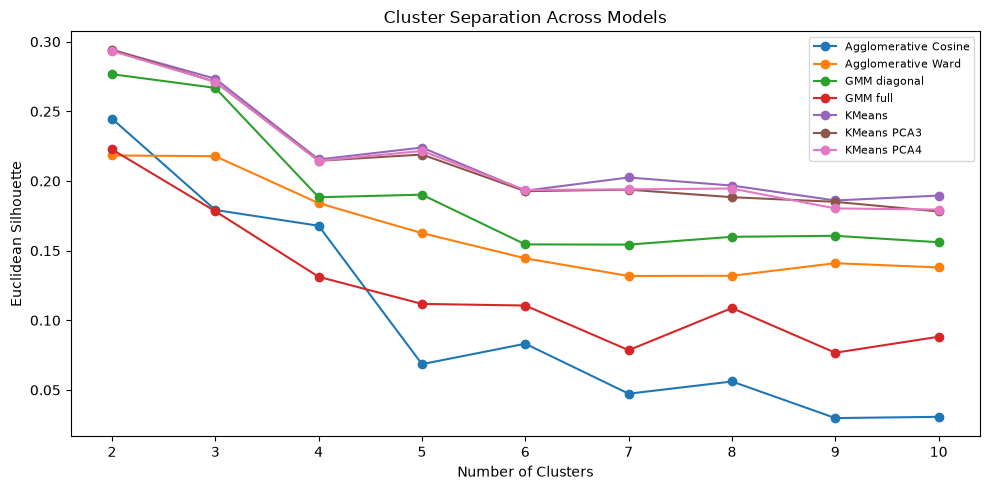

In [6]:
# Best solutions by Euclidean silhouette.
print("Highest Euclidean silhouette:")
display(
    results_df[results_df["k"] >= 2]
    .sort_values("Silhouette Euclidean", ascending=False)
    .head(12)
    .round(3)
)

# Best solutions by cosine silhouette.
print("Highest cosine silhouette:")
display(
    results_df[results_df["k"] >= 2]
    .sort_values("Silhouette Cosine", ascending=False)
    .head(12)
    .round(3)
)

# Best Gaussian Mixtures by BIC.
print("Lowest GMM BIC:")
display(
    results_df[results_df["BIC"].notna()]
    .sort_values("BIC")
    .head(10)
    .round(3)
)

# Compare cluster counts visually.
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, group in results_df[
    results_df["k"] >= 2
].groupby("Model"):

    ax.plot(
        group["k"],
        group["Silhouette Euclidean"],
        marker="o",
        label=model_name,
    )

ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Euclidean Silhouette")
ax.set_title("Cluster Separation Across Models")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [8]:
models = [
    "KMeans",
    "KMeans PCA4",
    "GMM diagonal",
    "Agglomerative Cosine",
]

shortlist = results_df[
    results_df["Model"].isin(models)
    & results_df["k"].between(3, 7)
].copy()


# Compare silhouette scores across models and cluster counts.
silhouette_table = shortlist.pivot(
    index="k",
    columns="Model",
    values="Silhouette Euclidean",
)

display(silhouette_table.round(3))


Model,Agglomerative Cosine,GMM diagonal,KMeans,KMeans PCA4
k,,,,
3,0.179,0.267,0.273,0.271
4,0.168,0.188,0.215,0.214
5,0.069,0.190,0.224,0.222
6,0.083,0.154,0.193,0.194
7,0.047,0.154,0.203,0.194


In [9]:
best_models = []

for name in models:

    subset = shortlist[
        shortlist["Model"] == name
    ]

    if name == "GMM diagonal":
        best_idx = subset["BIC"].idxmin()
    else:
        best_idx = subset["Silhouette Euclidean"].idxmax()

    best_models.append(shortlist.loc[best_idx])


best_models_df = pd.DataFrame(best_models)

display(
    best_models_df[
        [
            "Model",
            "k",
            "Silhouette Euclidean",
            "Davies-Bouldin",
            "Smallest cluster",
            "BIC",
        ]
    ].round(3)
)


,Model,k,Silhouette Euclidean,Davies-Bouldin,Smallest cluster,BIC
11,KMeans,3,0.273,1.264,93,NaN
13,KMeans PCA4,3,0.271,1.272,96,NaN
37,GMM diagonal,7,0.154,1.585,32,8223.974
15,Agglomerative Cosine,3,0.179,1.455,52,NaN


In [10]:
# Isolate the original KMeans results.
kmeans_results = (
    results_df[
        (results_df["Model"] == "KMeans")
        & (results_df["k"].between(2, 8))
    ]
    .sort_values("k")
    .copy()
)

# Display the metrics relevant to KMeans.
display(
    kmeans_results[
        [
            "k",
            "Inertia",
            "Silhouette Euclidean",
            "Davies-Bouldin",
            "Calinski-Harabasz",
            "Smallest cluster",
            "Largest cluster",
        ]
    ].round(3)
)

,k,Inertia,Silhouette Euclidean,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Largest cluster
4,2,2461.395,0.294,1.311,207.238,154,296
11,3,1923.137,0.273,1.264,194.879,93,215
18,4,1702.948,0.215,1.471,165.612,81,163
25,5,1538.340,0.224,1.324,149.096,67,162
32,6,1410.639,0.193,1.463,137.821,62,96
39,7,1311.972,0.203,1.414,128.762,29,97
46,8,1227.869,0.197,1.449,121.986,30,88


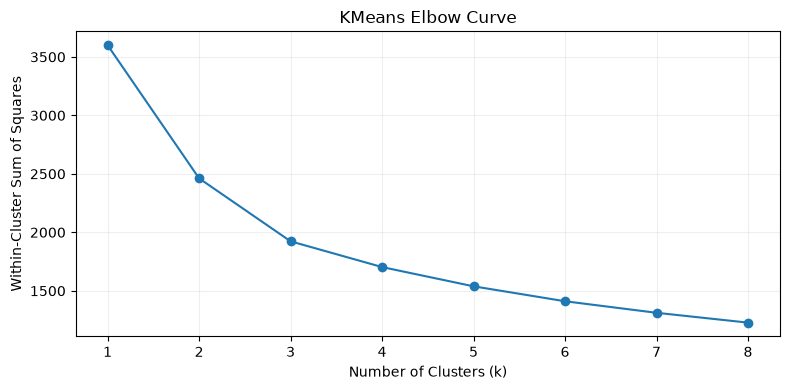

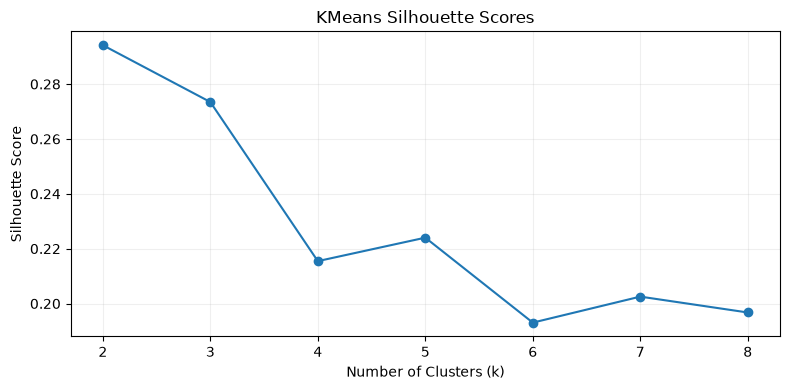

In [11]:
k1_model = KMeans(
    n_clusters=1,
    n_init=20,
    random_state=42,
).fit(X)

elbow_k = [1] + kmeans_results["k"].tolist()

elbow_inertia = [
    k1_model.inertia_
] + kmeans_results["Inertia"].tolist()


# Elbow curve.
plt.figure(figsize=(8, 4))

plt.plot(
    elbow_k,
    elbow_inertia,
    marker="o",
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("KMeans Elbow Curve")
plt.xticks(elbow_k)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# Silhouette curve.
plt.figure(figsize=(8, 4))

plt.plot(
    kmeans_results["k"],
    kmeans_results["Silhouette Euclidean"],
    marker="o",
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("KMeans Silhouette Scores")
plt.xticks(kmeans_results["k"])
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [12]:
for k in [3, 5, 7]:

    labels = fitted_models[("KMeans", k)]["labels"]

    comparison = players[
        ["PLAYER_ID", "PLAYER_NAME"] + offense_cols
    ].copy()

    comparison["cluster"] = labels

    profiles = (
        comparison.groupby("cluster")[offense_cols]
        .mean()
    )

    print(f"\nKMeans with k={k}")

    print("Cluster sizes:")
    display(
        comparison["cluster"]
        .value_counts()
        .sort_index()
    )

    print("Mean dimension scores:")
    display(profiles.round(2))



KMeans with k=3
Cluster sizes:


cluster
0     93
1    215
2    142
Name: count, dtype: int64

Mean dimension scores:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,-0.68,-0.62,0.01,0.09,-0.77,-1.20,1.41,1.07
1,-0.50,-0.44,0.22,-0.62,-0.45,0.65,-0.31,-0.09
2,1.20,1.07,-0.35,0.88,1.18,-0.20,-0.45,-0.56



KMeans with k=5
Cluster sizes:


cluster
0     77
1     67
2     70
3     74
4    162
Name: count, dtype: int64

... (2 outputs left out)


KMeans with k=7
Cluster sizes:


cluster
0    29
1    97
2    58
3    63
4    53
5    80
6    70
Name: count, dtype: int64

Mean dimension scores:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,0.72,0.44,-0.67,1.32,0.24,-1.05,1.52,-0.12
1,-0.72,-0.64,0.25,-0.38,-0.73,0.23,0.18,0.55
2,-0.92,-0.71,0.13,-0.08,-0.90,-1.59,1.57,1.48
3,1.67,1.56,-0.56,1.39,1.60,-0.37,-0.63,-0.59
4,0.61,0.95,1.14,-0.31,0.56,0.26,-0.72,-0.42
5,-0.71,-0.59,0.25,-1.12,-0.61,1.16,-0.66,-0.46
6,0.32,-0.14,-0.83,0.29,0.48,0.24,-0.32,-0.57


In [14]:
labels_3 = fitted_models[("KMeans", 3)]["labels"]
labels_5 = fitted_models[("KMeans", 5)]["labels"]
labels_7 = fitted_models[("KMeans", 7)]["labels"]

cluster_comparison = pd.crosstab(
    index=pd.Series(labels_3, name="k=3"),
    columns=[
        pd.Series(labels_5, name="k=5"),
        pd.Series(labels_7, name="k=7"),
    ],
)
display(cluster_comparison)
# Percentage of each k=3 group assigned to each k=5 group.
display(
    cluster_comparison.div(
        cluster_comparison.sum(axis=1),
        axis=0,
    ).mul(100).round(1)
)


k=5  0          1      2               3           4    
k=7  0  1   6   0   3  0  1  3   4  6  0   1   2   1   5
k=3                                                     
0    8  1   0   0   0  1  0  0   1  0  6  10  58   8   0
1    0  2  36   0   0  0  2  0  20  1  0   0   0  74  80
2    2  0  28  11  56  1  0  7  32  5  0   0   0   0   0

k=5    0               1          2                         3              \
k=7    0    1     6    0     3    0    1    3     4    6    0     1     2   
k=3                                                                         
0    8.6  1.1   0.0  0.0   0.0  1.1  0.0  0.0   1.1  0.0  6.5  10.8  62.4   
1    0.0  0.9  16.7  0.0   0.0  0.0  0.9  0.0   9.3  0.5  0.0   0.0   0.0   
2    1.4  0.0  19.7  7.7  39.4  0.7  0.0  4.9  22.5  3.5  0.0   0.0   0.0   

k=5     4        
k=7     1     5  
k=3              
0     8.6   0.0  
1    34.4  37.2  
2     0.0   0.0

In [15]:
labels_5 = fitted_models[("KMeans", 5)]["labels"]
labels_7 = fitted_models[("KMeans", 7)]["labels"]

model_7 = fitted_models[("KMeans", 7)]["model"]

# Clearer membership comparison.
display(
    pd.crosstab(
        pd.Series(labels_5, name="k=5"),
        pd.Series(labels_7, name="k=7"),
    )
)

# Examine representative players from the key new groups.
for cluster in [0, 1, 5]:

    indices = np.where(labels_7 == cluster)[0]

    center = model_7.cluster_centers_[cluster]

    distances = np.linalg.norm(
        X[indices] - center,
        axis=1,
    )

    closest = indices[np.argsort(distances)[:10]]

    representatives = players.iloc[closest][
        ["PLAYER_NAME", "USG_PCT"]
    ].copy()

    representatives["Previous k=5 Cluster"] = (
        labels_5[closest]
    )

    representatives["Centroid Distance"] = (
        distances[np.argsort(distances)[:10]]
    )

    print(f"\nk=7 Cluster {cluster}")
    display(representatives.round(3))

k=7,0,1,2,3,4,5,6
k=5,,,,,,,
0,10,3,0,0,0,0,64
1,11,0,0,56,0,0,0
2,2,2,0,7,53,0,6
3,6,10,58,0,0,0,0
4,0,82,0,0,0,80,0



k=7 Cluster 0


,PLAYER_NAME,USG_PCT,Previous k=5 Cluster,Centroid Distance
210,Jimmy Butler III,0.226,1,1.126
11,Alex Sarr,0.252,0,1.140
132,Evan Mobley,0.221,0,1.379
239,Julius Randle,0.258,1,1.384
103,Derik Queen,0.214,1,1.523
331,Nic Claxton,0.175,3,1.598
353,Paolo Banchero,0.274,1,1.604
354,Pascal Siakam,0.292,1,1.632
21,Anthony Davis,0.272,0,1.649
12,Alperen Sengun,0.259,1,1.692



k=7 Cluster 1


,PLAYER_NAME,USG_PCT,Previous k=5 Cluster,Centroid Distance
270,Kobe Brown,0.154,4,0.541
161,Jabari Walker,0.142,4,0.804
104,Derrick Jones Jr.,0.144,4,0.821
185,Jamir Watkins,0.148,4,0.960
388,Santi Aldama,0.191,4,0.995
25,Asa Newell,0.160,4,1.009
311,Micah Peavy,0.135,4,1.034
380,Ryan Dunn,0.136,4,1.050
410,Tidjane Salaün,0.147,4,1.050
150,Isaac Okoro,0.137,4,1.066



k=7 Cluster 5


,PLAYER_NAME,USG_PCT,Previous k=5 Cluster,Centroid Distance
283,Landry Shamet,0.151,4,0.606
258,Keon Ellis,0.129,4,0.680
131,Ethan Thompson,0.154,4,0.684
401,Svi Mykhailiuk,0.143,4,0.703
146,Harrison Barnes,0.144,4,0.703
386,Sam Merrill,0.167,4,0.810
436,Vít Krejčí,0.142,4,0.814
235,Julian Champagnie,0.146,4,0.853
319,Mohamed Diawara,0.169,4,0.870
241,Justin Edwards,0.154,4,0.899


In [16]:
from sklearn.metrics import silhouette_samples

for k in [5, 7]:

    labels = fitted_models[("KMeans", k)]["labels"]

    # Silhouette score for every individual player.
    player_silhouettes = silhouette_samples(X, labels)

    summary = pd.DataFrame({
        "Cluster": labels,
        "Silhouette": player_silhouettes,
    })

    cluster_summary = (
        summary.groupby("Cluster")
        .agg(
            Players=("Silhouette", "size"),
            Mean_Silhouette=("Silhouette", "mean"),
            Negative_Share=(
                "Silhouette",
                lambda x: (x < 0).mean(),
            ),
        )
    )

    print(f"\nKMeans k={k}")
    display(cluster_summary.round(3))


KMeans k=5


,Players,Mean_Silhouette,Negative_Share
Cluster,,,
0,77,0.199,0.000
1,67,0.161,0.104
2,70,0.208,0.000
3,74,0.296,0.054
4,162,0.236,0.000



KMeans k=7


,Players,Mean_Silhouette,Negative_Share
Cluster,,,
0,29,0.107,0.172
1,97,0.180,0.021
2,58,0.256,0.069
3,63,0.202,0.079
4,53,0.217,0.019
5,80,0.199,0.012
6,70,0.222,0.000


In [ ]:
# Original eight standardized offensive dimensions.
X = players[offense_cols].to_numpy()

# Fit PCA using all eight components.
pca_full = PCA()
pca_full.fit(X)

pca_summary = pd.DataFrame({
    "PC": range(1, X.shape[1] + 1),
    "Explained Variance": pca_full.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(
        pca_full.explained_variance_ratio_
    ),
})

display(pca_summary.round(3))

# Reduce eight dimensions to four principal components.
pca4 = PCA(n_components=4)

X_pca4 = pca4.fit_transform(X)

print("Original shape:", X.shape)
print("PCA shape:", X_pca4.shape)

print(
    "Explained variance:",
    round(pca4.explained_variance_ratio_.sum(), 3)
)


,PC,Explained Variance,Cumulative Variance
0,1,0.440,0.440
1,2,0.263,0.702
2,3,0.135,0.837
3,4,0.066,0.904
4,5,0.044,0.948
5,6,0.032,0.980
6,7,0.015,0.994
7,8,0.006,1.000


Original shape: (450, 8)
PCA shape: (450, 4)
Explained variance: 0.904


In [19]:
pca_results = []
pca_models = {}

for k in range(1, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20,
    )

    labels = model.fit_predict(X_pca4)

    pca_models[k] = model

    if k >= 2:
        silhouette_pca = silhouette_score(
            X_pca4, labels
        )

        silhouette_original = silhouette_score(
            X, labels
        )
    else:
        silhouette_pca = np.nan
        silhouette_original = np.nan

    sizes = pd.Series(labels).value_counts()

    pca_results.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette PCA": silhouette_pca,
        "Silhouette Original": silhouette_original,
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
    })

pca_results_df = pd.DataFrame(pca_results)

display(pca_results_df.round(3))

,k,Inertia,Silhouette PCA,Silhouette Original,Smallest Cluster,Largest Cluster
0,1,3253.347,NaN,NaN,450,450
1,2,2115.272,0.326,0.293,156,294
2,3,1579.426,0.309,0.271,96,214
3,4,1365.723,0.253,0.214,82,160
4,5,1204.243,0.263,0.222,59,161
5,6,1081.169,0.237,0.194,62,103
6,7,987.470,0.242,0.194,37,101
7,8,897.522,0.244,0.195,31,96


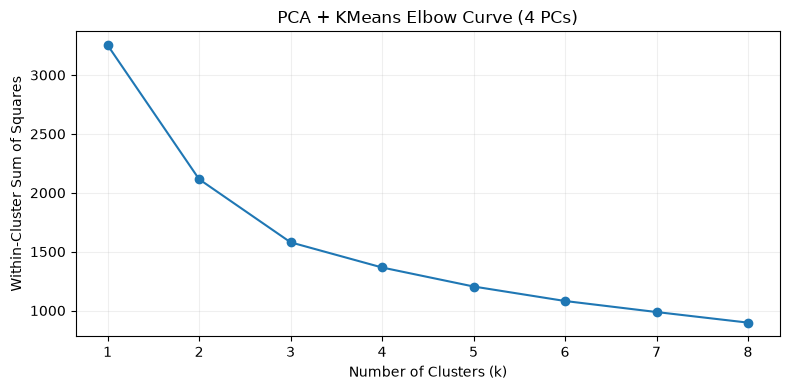

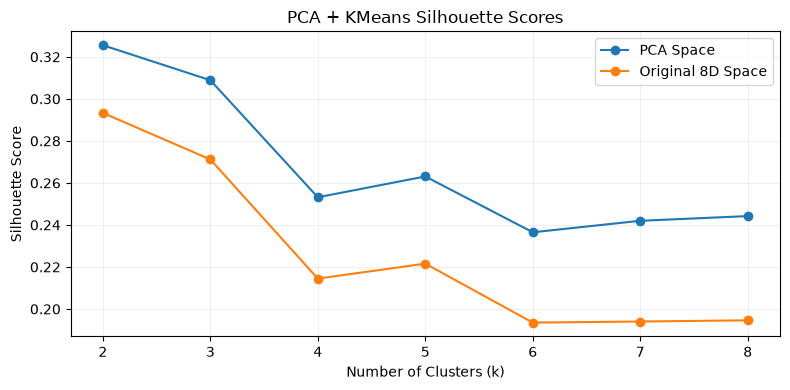

In [20]:
plt.figure(figsize=(8, 4))

plt.plot(
    pca_results_df["k"],
    pca_results_df["Inertia"],
    marker="o",
)

plt.title("PCA + KMeans Elbow Curve (4 PCs)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.xticks(range(1, 9))
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


# PCA + KMeans silhouette scores.

plot_data = pca_results_df[
    pca_results_df["k"] >= 2
]

plt.figure(figsize=(8, 4))

plt.plot(
    plot_data["k"],
    plot_data["Silhouette PCA"],
    marker="o",
    label="PCA Space",
)

plt.plot(
    plot_data["k"],
    plot_data["Silhouette Original"],
    marker="o",
    label="Original 8D Space",
)

plt.title("PCA + KMeans Silhouette Scores")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


In [21]:
component_weights = pd.DataFrame(
    pca4.components_.T,
    index=offensive_dimensions,
    columns=["PC1", "PC2", "PC3", "PC4"],
)

display(component_weights.round(2))

,PC1,PC2,PC3,PC4
BALL_DOMINANCE,0.51,-0.03,0.04,-0.02
PLAYMAKING,0.45,0.02,0.42,-0.07
BALL_MOVEMENT,-0.17,0.20,0.84,-0.17
RIM_PRESSURE,0.37,-0.40,-0.03,0.02
ON_BALL_CREATION,0.49,0.01,-0.01,0.33
PERIMETER_SHOOTING,-0.05,0.61,-0.23,0.13
INTERIOR_OFFENSE,-0.19,-0.55,-0.06,-0.44
OFFENSIVE_REBOUNDING,-0.30,-0.35,0.23,0.80


In [22]:
for k in [5, 7]:

    original_labels = fitted_models[
        ("KMeans", k)
    ]["labels"]

    pca_labels = pca_models[k].labels_

    ari = adjusted_rand_score(
        original_labels,
        pca_labels,
    )

    print(f"\nk={k}")
    print(f"Adjusted Rand Index: {ari:.3f}")

    # Compare cluster memberships.
    comparison = pd.crosstab(
        pd.Series(original_labels, name="Original KMeans"),
        pd.Series(pca_labels, name="PCA KMeans"),
    )

    display(comparison)

    # Interpret PCA clusters in original basketball dimensions.
    profiles = (
        players[offense_cols]
        .groupby(pd.Series(pca_labels, name="Cluster"))
        .mean()
    )

    print("PCA cluster profiles:")
    display(profiles.round(2))



k=5
Adjusted Rand Index: 0.942


PCA KMeans,0,1,2,3,4
Original KMeans,,,,,
0,0,75,0,2,0
1,0,1,0,0,66
2,59,2,0,0,9
3,0,0,0,74,0
4,0,0,161,1,0


PCA cluster profiles:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
Cluster,,,,,,,,
0,0.56,0.88,1.08,-0.23,0.53,0.20,-0.69,-0.39
1,0.34,-0.14,-0.91,0.32,0.42,0.16,-0.06,-0.54
2,-0.74,-0.62,0.28,-0.79,-0.68,0.74,-0.28,0.07
3,-0.77,-0.66,0.02,0.05,-0.84,-1.37,1.49,1.21
4,1.58,1.47,-0.52,1.49,1.46,-0.51,-0.33,-0.52



k=7
Adjusted Rand Index: 0.832


PCA KMeans,0,1,2,3,4,5,6
Original KMeans,,,,,,,
0,0,4,0,15,0,10,0
1,0,0,0,3,93,0,1
2,37,0,0,19,2,0,0
3,0,1,0,0,0,62,0
4,0,0,0,0,0,0,53
5,0,0,74,0,6,0,0
6,0,67,0,0,0,0,3


PCA cluster profiles:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
Cluster,,,,,,,,
0,-1.03,-0.75,0.18,-0.10,-0.83,-1.55,1.50,2.16
1,0.38,-0.13,-0.94,0.31,0.49,0.24,-0.20,-0.55
2,-0.69,-0.57,0.26,-1.11,-0.60,1.20,-0.69,-0.51
3,-0.22,-0.35,-0.24,0.49,-0.66,-1.41,1.72,0.08
4,-0.77,-0.67,0.26,-0.46,-0.74,0.25,0.13,0.57
5,1.60,1.51,-0.53,1.48,1.50,-0.48,-0.37,-0.54
6,0.58,0.89,1.09,-0.25,0.55,0.23,-0.72,-0.41


,k,BIC,AIC,Silhouette Euclidean,Smallest cluster
0,1,10314.11,10248.36,NaN,450
2,2,8996.53,8860.93,0.28,181
9,3,8664.33,8458.87,0.27,71
16,4,8421.54,8146.23,0.19,58
23,5,8318.24,7973.07,0.19,59
30,6,8251.10,7836.07,0.15,41
37,7,8223.97,7739.08,0.15,32
44,8,8210.18,7655.43,0.16,9


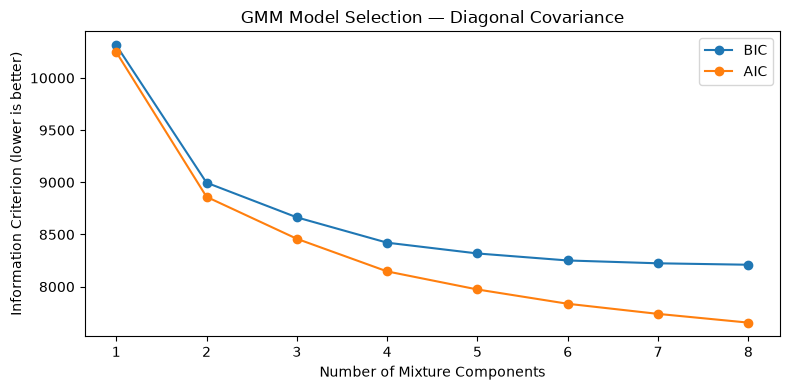

In [23]:
gmm_results = (
    results_df[
        (results_df["Model"] == "GMM diagonal")
        & results_df["k"].between(1, 8)
    ]
    .sort_values("k")
    .copy()
)

display(
    gmm_results[
        [
            "k",
            "BIC",
            "AIC",
            "Silhouette Euclidean",
            "Smallest cluster",
        ]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    gmm_results["k"],
    gmm_results["BIC"],
    marker="o",
    label="BIC",
)

ax.plot(
    gmm_results["k"],
    gmm_results["AIC"],
    marker="o",
    label="AIC",
)

ax.set_title("GMM Model Selection — Diagonal Covariance")
ax.set_xlabel("Number of Mixture Components")
ax.set_ylabel("Information Criterion (lower is better)")
ax.legend()

plt.tight_layout()
plt.show()


,Full BIC,Diagonal BIC
k,,
1,7687.80,10314.11
2,7390.24,8996.53
3,7347.90,8664.33
4,7498.76,8421.54
5,7648.59,8318.24
6,7822.38,8251.10
7,7952.71,8223.97
8,8177.14,8210.18


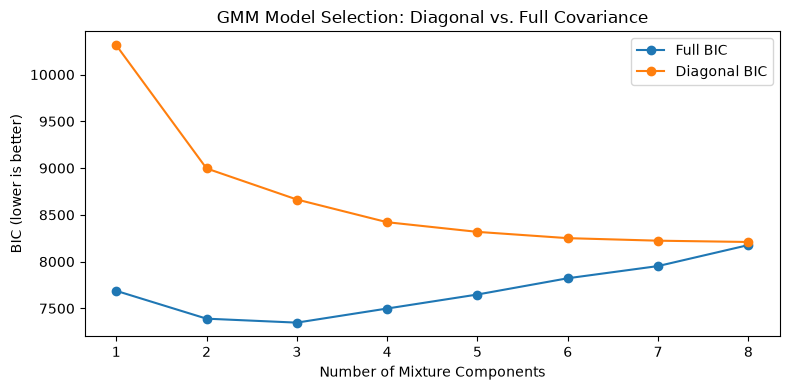

In [24]:
full_results = []
full_models = {}

for k in range(1, 9):

    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        reg_covar=1e-4,
        n_init=3,
        random_state=42,
    )

    model.fit(X)

    full_models[k] = model

    full_results.append({
        "k": k,
        "BIC": model.bic(X),
        "AIC": model.aic(X),
        "Converged": model.converged_,
    })

full_results_df = pd.DataFrame(full_results)

# Compare with our existing diagonal GMM results.
diagonal_bic = (
    gmm_results.set_index("k")["BIC"]
)

comparison = full_results_df.set_index("k")[
    ["BIC"]
].rename(columns={"BIC": "Full BIC"})

comparison["Diagonal BIC"] = diagonal_bic

display(comparison.round(2))

ax = comparison.plot(
    marker="o",
    figsize=(8, 4),
)

ax.set_title("GMM Model Selection: Diagonal vs. Full Covariance")
ax.set_xlabel("Number of Mixture Components")
ax.set_ylabel("BIC (lower is better)")
ax.set_xticks(range(1, 9))

plt.tight_layout()
plt.show()


In [25]:
# Retrieve our best full-covariance GMM.
gmm = full_models[3]

# Hard assignments and membership probabilities.
gmm_labels = gmm.predict(X)
gmm_probabilities = gmm.predict_proba(X)

print("Converged:", gmm.converged_)
print("Iterations:", gmm.n_iter_)

print("\nComponent weights:")
display(
    pd.Series(
        gmm.weights_,
        name="Estimated Weight"
    ).round(3)
)

print("\nAssigned cluster sizes:")
display(
    pd.Series(gmm_labels)
    .value_counts()
    .sort_index()
    .rename("Players")
    .to_frame()
)

print(
    "\nEuclidean silhouette:",
    round(silhouette_score(X, gmm_labels), 3)
)


Converged: True
Iterations: 15

Component weights:


0    0.229
1    0.411
2    0.360
Name: Estimated Weight, dtype: float64


Assigned cluster sizes:


,Players
0,100
1,195
2,155



Euclidean silhouette: 0.178


In [26]:

gmm_profiles = (
    players[offense_cols]
    .assign(cluster=gmm_labels)
    .groupby("cluster")
    .mean()
)

display(gmm_profiles.round(2))

# Representative players based on distance
# to each group's mean profile.
for cluster, profile in gmm_profiles.iterrows():

    indices = np.where(gmm_labels == cluster)[0]

    distances = np.linalg.norm(
        X[indices] - profile.to_numpy(),
        axis=1,
    )

    closest = indices[np.argsort(distances)[:8]]

    print(f"\nGMM Cluster {cluster}")

    display(
        players.iloc[closest][
            ["PLAYER_NAME", "USG_PCT"]
        ]
    )


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,-0.74,-0.63,0.03,-0.14,-0.88,-0.87,1.34,1.04
1,-0.39,-0.39,0.15,-0.46,-0.24,0.55,-0.57,-0.10
2,0.97,0.90,-0.20,0.67,0.87,-0.13,-0.15,-0.55



GMM Cluster 0


,PLAYER_NAME,USG_PCT
206,Jeremy Sochan,0.141
23,Anthony Gill,0.116
438,Wendell Carter Jr.,0.156
251,Kel'el Ware,0.174
214,John Collins,0.188
165,Jae'Sean Tate,0.131
113,Donovan Clingan,0.163
299,Malevy Leons,0.137



GMM Cluster 1


,PLAYER_NAME,USG_PCT
423,Tristan da Silva,0.160
357,Patrick Williams,0.159
241,Justin Edwards,0.154
254,Kelly Oubre Jr.,0.179
271,Kobe Sanders,0.155
187,Jarace Walker,0.200
160,Jabari Smith Jr.,0.179
62,Cameron Johnson,0.144



GMM Cluster 2


,PLAYER_NAME,USG_PCT
279,Kyshawn George,0.222
8,Ajay Mitchell,0.210
89,Daniss Jenkins,0.209
234,Jrue Holiday,0.227
366,Quenton Jackson,0.200
430,Tyrese Proctor,0.214
27,Austin Reaves,0.258
193,Javon Small,0.183


In [27]:

# Sort each player's membership probabilities.
sorted_probs = np.sort(
    gmm_probabilities,
    axis=1,
)

membership = players[
    ["PLAYER_NAME"]
].copy()

membership["Primary Cluster"] = gmm_labels

membership["Primary Probability"] = (
    sorted_probs[:, -1]
)

membership["Secondary Probability"] = (
    sorted_probs[:, -2]
)

print("Membership confidence summary:")
display(
    membership[
        [
            "Primary Probability",
            "Secondary Probability",
        ]
    ].describe().round(3)
)

print(
    "Players with primary probability below 0.60:",
    (membership["Primary Probability"] < 0.60).sum()
)

# Examine players with the most ambiguous assignments.
display(
    membership.nsmallest(
        15,
        "Primary Probability",
    ).round(3)
)


Membership confidence summary:


,Primary Probability,Secondary Probability
count,450.000,450.000
mean,0.928,0.070
std,0.118,0.115
min,0.499,0.000
25%,0.905,0.000
50%,0.990,0.010
75%,1.000,0.092
max,1.000,0.493


Players with primary probability below 0.60: 12


,PLAYER_NAME,Primary Cluster,Primary Probability,Secondary Probability
90,Danny Wolf,2,0.499,0.493
112,Dominick Barlow,0,0.512,0.487
325,Myles Turner,0,0.535,0.465
96,De'Anthony Melton,1,0.539,0.461
300,Malik Monk,1,0.546,0.454
426,Tyler Herro,1,0.562,0.438
259,Keshad Johnson,1,0.565,0.403
137,Gary Payton II,2,0.573,0.427
308,Max Strus,0,0.579,0.418
288,Leonard Miller,2,0.581,0.216


Minimum profile norm: 0.7368018763599238
Median profile norm: 2.5735028418127106


,k,Silhouette Cosine,Silhouette Euclidean,Smallest Cluster,Largest Cluster
0,3,0.330,0.179,52,235
1,4,0.344,0.168,52,163
2,5,0.312,0.069,6,157
3,6,0.305,0.083,6,129
4,7,0.305,0.047,6,129
5,8,0.308,0.056,6,129


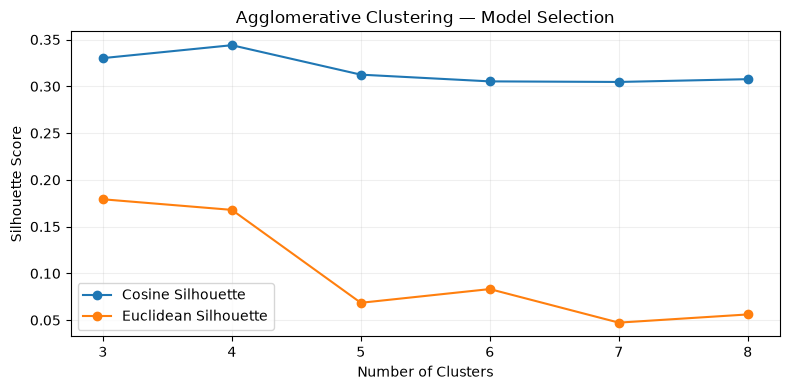

In [28]:
# Check profile magnitudes before using cosine distance.
profile_norms = np.linalg.norm(X, axis=1)

print("Minimum profile norm:", profile_norms.min())
print("Median profile norm:", np.median(profile_norms))

if (profile_norms == 0).any():
    raise ValueError("Cosine distance is undefined for zero vectors.")

agg_results = []
agg_models = {}

for k in range(3, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        metric="cosine",
        linkage="average",
    )

    labels = model.fit_predict(X)

    agg_models[k] = labels

    sizes = pd.Series(labels).value_counts()

    agg_results.append({
        "k": k,
        "Silhouette Cosine": silhouette_score(
            X, labels, metric="cosine"
        ),
        "Silhouette Euclidean": silhouette_score(
            X, labels, metric="euclidean"
        ),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
    })

agg_results_df = pd.DataFrame(agg_results)

display(agg_results_df.round(3))


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    agg_results_df["k"],
    agg_results_df["Silhouette Cosine"],
    marker="o",
    label="Cosine Silhouette",
)

ax.plot(
    agg_results_df["k"],
    agg_results_df["Silhouette Euclidean"],
    marker="o",
    label="Euclidean Silhouette",
)

ax.set_title("Agglomerative Clustering — Model Selection")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(range(3, 9))
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


,k,BIC,AIC,Silhouette,Smallest Cluster,Largest Cluster,Converged
0,3,7486.470,7231.697,0.261,60,260,True
1,4,7440.205,7148.448,0.230,46,216,True
2,5,7409.110,7080.370,0.190,35,215,True
3,6,7387.217,7021.494,0.142,16,191,True
4,7,7401.107,6998.401,0.127,16,148,True
5,8,7423.647,6983.957,0.121,11,117,True


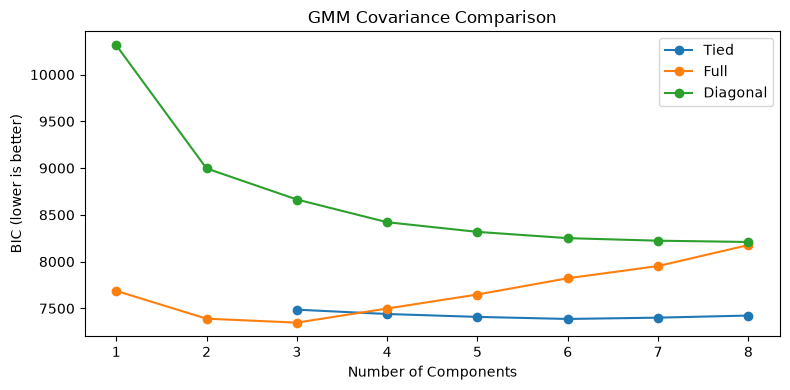

In [29]:
tied_results = []
tied_models = {}

for k in range(3, 9):

    model = GaussianMixture(
        n_components=k,
        covariance_type="tied",
        reg_covar=1e-4,
        n_init=5,
        random_state=42,
    )

    labels = model.fit_predict(X)

    tied_models[k] = model

    sizes = pd.Series(labels).value_counts()

    tied_results.append({
        "k": k,
        "BIC": model.bic(X),
        "AIC": model.aic(X),
        "Silhouette": (
            silhouette_score(X, labels)
            if len(sizes) > 1 else np.nan
        ),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
        "Converged": model.converged_,
    })

tied_results_df = pd.DataFrame(tied_results)

display(tied_results_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    tied_results_df["k"],
    tied_results_df["BIC"],
    marker="o",
    label="Tied",
)

ax.plot(
    comparison.index,
    comparison["Full BIC"],
    marker="o",
    label="Full",
)

ax.plot(
    comparison.index,
    comparison["Diagonal BIC"],
    marker="o",
    label="Diagonal",
)

ax.set_title("GMM Covariance Comparison")
ax.set_xlabel("Number of Components")
ax.set_ylabel("BIC (lower is better)")
ax.set_xticks(range(1, 9))
ax.legend()

plt.tight_layout()
plt.show()


In [30]:
for k in [5, 6]:

    model = tied_models[k]
    labels = model.predict(X)

    comparison = players[
        ["PLAYER_NAME"] + offense_cols
    ].copy()

    comparison["cluster"] = labels

    profiles = comparison.groupby("cluster")[offense_cols].mean()

    print(f"\nTied GMM | k={k}")

    # Cluster sizes.
    display(
        comparison["cluster"]
        .value_counts()
        .sort_index()
        .rename("Players")
        .to_frame()
    )

    # Average offensive profiles.
    display(profiles.round(2))

    # Five representative players per component.
    representatives = []

    for cluster, group in comparison.groupby("cluster"):

        center = profiles.loc[cluster].to_numpy()

        distances = np.linalg.norm(
            group[offense_cols].to_numpy() - center,
            axis=1,
        )

        nearest = group.iloc[np.argsort(distances)[:5]]

        representatives.append({
            "Cluster": cluster,
            "Players": ", ".join(nearest["PLAYER_NAME"]),
        })

    display(pd.DataFrame(representatives))


Tied GMM | k=5


,Players
cluster,
0,43
1,35
2,97
3,60
4,215


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,0.37,0.12,-0.66,0.39,0.36,-0.29,1.21,-0.05
1,1.69,2.31,-0.04,0.96,1.58,-0.27,-0.55,-0.63
2,0.96,0.77,0.20,0.45,0.94,0.03,-0.72,-0.44
3,-0.82,-0.69,0.02,0.02,-0.94,-1.64,1.63,1.26
4,-0.55,-0.55,0.04,-0.44,-0.49,0.55,-0.28,-0.04


,Cluster,Players
0,0,"Bam Adebayo, Alex Sarr, Chet Holmgren, Tobias ..."
1,1,"De'Aaron Fox, Dejounte Murray, Andrew Nembhard..."
2,2,"Kyshawn George, Caris LeVert, Brandin Podziems..."
3,3,"Neemias Queta, Isaiah Jackson, Rudy Gobert, Lu..."
4,4,"Tristan da Silva, Patrick Williams, Kelly Oubr..."



Tied GMM | k=6


,Players
cluster,
0,61
1,37
2,191
3,92
4,53
5,16


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,-0.31,-0.44,-0.22,-0.26,-0.66,0.23,1.14,0.32
1,1.59,2.18,0.00,1.16,1.54,-0.36,-0.71,-0.66
2,-0.54,-0.51,0.10,-0.47,-0.37,0.53,-0.41,-0.03
3,1.01,0.69,-0.07,0.38,1.03,0.12,-0.78,-0.53
4,-0.85,-0.71,0.05,0.03,-0.97,-1.77,1.67,1.23
5,0.96,1.14,-0.12,1.63,0.66,-1.14,1.19,-0.26


,Cluster,Players
0,0,"Sandro Mamukelashvili, Kyle Filipowski, Onyeka..."
1,1,"De'Aaron Fox, Dejounte Murray, Andrew Nembhard..."
2,2,"Tristan da Silva, Patrick Williams, Kelly Oubr..."
3,3,"Ousmane Dieng, Kyshawn George, Anthony Black, ..."
4,4,"Neemias Queta, Isaiah Jackson, Rudy Gobert, Lu..."
5,5,"Jimmy Butler III, Scottie Barnes, Paolo Banche..."


In [31]:
kmeans_labels = fitted_models[("KMeans", 7)]["labels"]
gmm_labels = tied_models[6].predict(X)

# Overall agreement between the two solutions.
print(
    "Adjusted Rand Index:",
    round(adjusted_rand_score(kmeans_labels, gmm_labels), 3)
)

# Compare memberships across models.
overlap = pd.crosstab(
    pd.Series(kmeans_labels, name="KMeans k=7"),
    pd.Series(gmm_labels, name="Tied GMM k=6"),
)

display(overlap)

# Inspect overlap between the two interior-creator groups.
kmeans_interior = set(
    players.loc[kmeans_labels == 0, "PLAYER_ID"]
)

gmm_interior = set(
    players.loc[gmm_labels == 5, "PLAYER_ID"]
)

shared = kmeans_interior & gmm_interior

print("KMeans interior creators:", len(kmeans_interior))
print("GMM interior creators:", len(gmm_interior))
print("Shared players:", len(shared))

Adjusted Rand Index: 0.303


Tied GMM k=6,0,1,2,3,4,5
KMeans k=7,,,,,,
0,9,0,2,1,5,12
1,30,0,67,0,0,0
2,9,0,0,0,48,1
3,0,29,0,32,0,2
4,1,8,8,35,0,1
5,5,0,73,2,0,0
6,7,0,41,22,0,0


KMeans interior creators: 29
GMM interior creators: 16
Shared players: 12


In [32]:

from sklearn.metrics.pairwise import cosine_distances

# Retrieve the previously fitted k=4 assignments.
agg_labels = agg_models[4]

comparison = players[
    ["PLAYER_NAME", "USG_PCT"] + offense_cols
].copy()

comparison["cluster"] = agg_labels

# Cluster sizes.
print("Cluster sizes:")
display(
    comparison["cluster"]
    .value_counts()
    .sort_index()
    .rename("Players")
    .to_frame()
)

# Average profiles in our original eight dimensions.
agg_profiles = (
    comparison.groupby("cluster")[offense_cols]
    .mean()
)

print("Cluster profiles:")
display(agg_profiles.round(2))

# Find five representative players per cluster.
for cluster, group in comparison.groupby("cluster"):

    # Pairwise cosine distances within this cluster.
    distances = cosine_distances(
        group[offense_cols]
    )

    # Lower average distance = more central player.
    average_distance = distances.mean(axis=1)

    nearest = group.iloc[
        np.argsort(average_distance)[:5]
    ][["PLAYER_NAME", "USG_PCT"]].copy()

    nearest["Mean Cosine Distance"] = (
        np.sort(average_distance)[:5]
    )

    print(f"\nAgglomerative Cluster {cluster}")
    display(nearest.round(3))


Cluster sizes:


,Players
cluster,
0,163
1,106
2,52
3,129


Cluster profiles:


,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,0.99,0.69,-0.64,0.89,0.94,-0.20,-0.15,-0.49
1,-0.69,-0.63,0.01,-0.85,-0.52,0.86,-0.59,-0.23
2,0.29,0.78,1.40,-0.46,0.25,0.32,-0.74,-0.35
3,-0.80,-0.67,0.23,-0.23,-0.86,-0.58,0.97,0.95



Agglomerative Cluster 0


,PLAYER_NAME,USG_PCT,Mean Cosine Distance
114,Donovan Mitchell,0.311,0.377
79,Collin Sexton,0.248,0.384
392,Shai Gilgeous-Alexander,0.323,0.390
74,Coby White,0.283,0.392
429,Tyrese Maxey,0.286,0.401


... (2 outputs left out)


Agglomerative Cluster 2


,PLAYER_NAME,USG_PCT,Mean Cosine Distance
432,Tyus Jones,0.103,0.291
297,Malachi Smith,0.136,0.299
174,Jalen Pickett,0.148,0.299
224,Jordan McLaughlin,0.143,0.311
257,Kentavious Caldwell-Pope,0.173,0.313



Agglomerative Cluster 3


,PLAYER_NAME,USG_PCT,Mean Cosine Distance
23,Anthony Gill,0.116,0.336
72,Christian Koloko,0.109,0.340
309,Maxi Kleber,0.092,0.340
438,Wendell Carter Jr.,0.156,0.342
322,Mouhamed Gueye,0.120,0.346


In [33]:
kmeans_labels = fitted_models[
    ("KMeans", 7)
]["labels"]

print(
    "Adjusted Rand Index:",
    round(
        adjusted_rand_score(
            kmeans_labels,
            agg_labels,
        ),
        3,
    )
)

display(
    pd.crosstab(
        pd.Series(kmeans_labels, name="KMeans k=7"),
        pd.Series(agg_labels, name="Agglomerative k=4"),
    )
)


Adjusted Rand Index: 0.385


Agglomerative k=4,0,1,2,3
KMeans k=7,,,,
0,26,0,1,2
1,0,31,3,63
2,0,0,1,57
3,62,0,1,0
4,12,2,38,1
5,0,66,8,6
6,63,7,0,0


,k,Silhouette Euclidean,Silhouette Cosine,Smallest Cluster,Largest Cluster
0,3,0.295,-0.102,1,448
1,4,0.242,0.070,1,309
2,5,0.244,0.097,1,228
3,6,0.236,0.066,1,228
4,7,0.216,-0.021,1,228


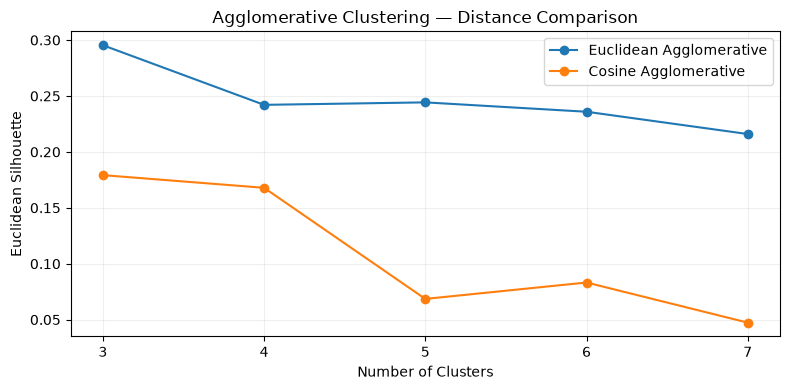

In [34]:
euclidean_results = []
euclidean_models = {}

for k in range(3, 8):

    model = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="average",
    )

    labels = model.fit_predict(X)

    euclidean_models[k] = labels

    sizes = pd.Series(labels).value_counts()

    euclidean_results.append({
        "k": k,
        "Silhouette Euclidean": silhouette_score(
            X, labels, metric="euclidean"
        ),
        "Silhouette Cosine": silhouette_score(
            X, labels, metric="cosine"
        ),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
    })

euclidean_results_df = pd.DataFrame(euclidean_results)

display(euclidean_results_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    euclidean_results_df["k"],
    euclidean_results_df["Silhouette Euclidean"],
    marker="o",
    label="Euclidean Agglomerative",
)

cosine_results = agg_results_df[
    agg_results_df["k"].between(3, 7)
]

ax.plot(
    cosine_results["k"],
    cosine_results["Silhouette Euclidean"],
    marker="o",
    label="Cosine Agglomerative",
)

ax.set_title("Agglomerative Clustering — Distance Comparison")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Euclidean Silhouette")
ax.set_xticks(range(3, 8))
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


,k,WCSS,Silhouette,Davies-Bouldin,Smallest Cluster,Largest Cluster
0,3,2203.856,0.218,1.285,52,236
1,4,1870.926,0.184,1.505,52,175
2,5,1708.612,0.163,1.714,52,162
3,6,1568.044,0.145,1.685,52,97
4,7,1475.069,0.132,1.621,28,97
5,8,1386.907,0.132,1.640,28,87


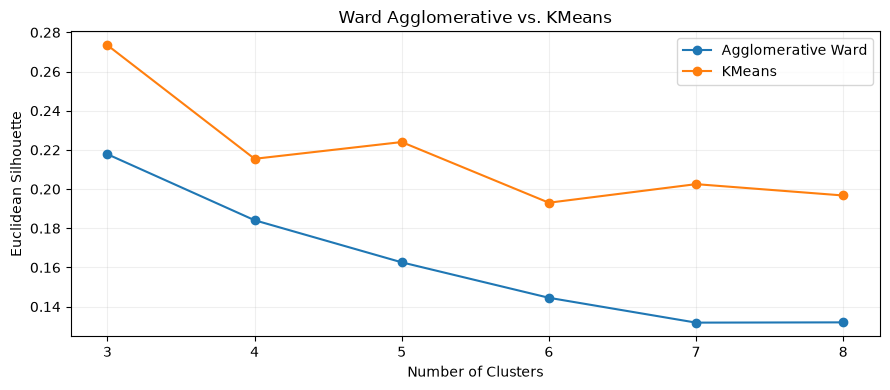

In [36]:
ward_results = []
ward_labels = {}

for k in range(3, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward",
        metric="euclidean",
    )

    labels = model.fit_predict(X)
    ward_labels[k] = labels

    sizes = pd.Series(labels).value_counts()

    # Calculate within-cluster sum of squares.
    centers = (
        pd.DataFrame(X)
        .assign(cluster=labels)
        .groupby("cluster")
        .mean()
    )

    wcss = np.sum(
        (X - centers.loc[labels].to_numpy()) ** 2
    )

    ward_results.append({
        "k": k,
        "WCSS": wcss,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
    })

ward_results_df = pd.DataFrame(ward_results)

display(ward_results_df.round(3))

kmeans_comparison = results_df[
    (results_df["Model"] == "KMeans")
    & results_df["k"].between(3, 8)
].sort_values("k")

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    ward_results_df["k"],
    ward_results_df["Silhouette"],
    marker="o",
    label="Agglomerative Ward",
)

ax.plot(
    kmeans_comparison["k"],
    kmeans_comparison["Silhouette Euclidean"],
    marker="o",
    label="KMeans",
)

ax.set_title("Ward Agglomerative vs. KMeans")
ax.set_xlabel("Number of Clusters")
ax.set_ylabel("Euclidean Silhouette")
ax.set_xticks(range(3, 9))
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [37]:
rng = np.random.default_rng(28)

stability_results = []

for k in [5, 7]:

    reference_labels = fitted_models[
        ("KMeans", k)
    ]["labels"]

    ari_scores = []

    for iteration in range(30):

        # Randomly select 80% of players.
        indices = rng.choice(
            len(X),
            size=int(0.80 * len(X)),
            replace=False,
        )

        X_sub = X[indices]

        # Refit KMeans using the subsample.
        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20,
        )

        sub_labels = model.fit_predict(X_sub)

        # Compare only the same players.
        ari = adjusted_rand_score(
            reference_labels[indices],
            sub_labels,
        )

        ari_scores.append(ari)

    stability_results.append({
        "k": k,
        "Mean ARI": np.mean(ari_scores),
        "SD ARI": np.std(ari_scores),
        "Minimum ARI": np.min(ari_scores),
        "Maximum ARI": np.max(ari_scores),
    })

display(
    pd.DataFrame(stability_results).round(3)
)

,k,Mean ARI,SD ARI,Minimum ARI,Maximum ARI
0,5,0.891,0.077,0.670,0.990
1,7,0.842,0.078,0.719,0.971


In [38]:

reference_labels = fitted_models[
    ("KMeans", 7)
]["labels"]

# Original interior-oriented creator cluster.
target_cluster = 0

rng = np.random.default_rng(42)

jaccard_scores = []

for iteration in range(30):

    indices = rng.choice(
        len(X),
        size=int(0.80 * len(X)),
        replace=False,
    )

    sub_labels = KMeans(
        n_clusters=7,
        n_init=20,
        random_state=42,
    ).fit_predict(X[indices])

    # Original group among sampled players.
    reference_group = set(
        indices[reference_labels[indices] == target_cluster]
    )

    # Find the best-matching new group.
    overlaps = []

    for cluster in range(7):

        new_group = set(
            indices[sub_labels == cluster]
        )

        intersection = len(reference_group & new_group)
        union = len(reference_group | new_group)

        overlaps.append(
            intersection / union if union else 0
        )

    jaccard_scores.append(max(overlaps))

print(
    "Mean Jaccard:",
    round(np.mean(jaccard_scores), 3)
)

print(
    "Minimum Jaccard:",
    round(np.min(jaccard_scores), 3)
)

print(
    "SD Jaccard:",
    round(np.std(jaccard_scores), 3)
)


Mean Jaccard: 0.495
Minimum Jaccard: 0.14
SD Jaccard: 0.3


In [39]:

rng = np.random.default_rng(28)

cluster_stability = []

for k in [5, 7]:

    reference_labels = fitted_models[
        ("KMeans", k)
    ]["labels"]

    for iteration in range(30):

        indices = rng.choice(
            len(X),
            size=int(0.80 * len(X)),
            replace=False,
        )

        new_labels = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=42,
        ).fit_predict(X[indices])

        # Compare each original cluster with its
        # best-matching cluster in the subsample.
        for original_cluster in range(k):

            original_group = (
                reference_labels[indices] == original_cluster
            )

            jaccard_scores = []

            for new_cluster in range(k):

                new_group = (new_labels == new_cluster)

                intersection = (
                    original_group & new_group
                ).sum()

                union = (
                    original_group | new_group
                ).sum()

                jaccard_scores.append(
                    intersection / union if union else 0
                )

            cluster_stability.append({
                "k": k,
                "Cluster": original_cluster,
                "Jaccard": max(jaccard_scores),
            })


stability_df = pd.DataFrame(cluster_stability)

stability_summary = (
    stability_df
    .groupby(["k", "Cluster"])["Jaccard"]
    .agg(
        Mean="mean",
        SD="std",
        Minimum="min",
    )
)

display(stability_summary.round(3))


Mean     SD  Minimum
k Cluster                       
5 0        0.852  0.136    0.538
  1        0.896  0.078    0.700
  2        0.849  0.077    0.638
  3        0.945  0.057    0.794
  4        0.944  0.053    0.799
7 0        0.515  0.305    0.133
  1        0.895  0.053    0.776
  2        0.795  0.184    0.512
  3        0.807  0.157    0.557
  4        0.835  0.160    0.492
  5        0.923  0.053    0.808
  6        0.903  0.062    0.761

In [40]:

# Final offensive archetype names.
OFFENSE_ARCHETYPES = {
    0: "Interior-Oriented Creators",
    1: "Complementary Support Players",
    2: "Interior Finishers & Rebounders",
    3: "High-Involvement Creators",
    4: "Ball-Movement Creators",
    5: "Perimeter Spacers",
    6: "Secondary Scoring Attackers",
}

# Retrieve our selected KMeans assignments.
kmeans_labels = fitted_models[("KMeans", 7)]["labels"]

# Build a player-level dataset for Phase 4.
offense_players = players[
    ["PLAYER_ID", "PLAYER_NAME", "USG_PCT"] + offense_cols
].copy().reset_index(drop=True)

offense_players["OFFENSE_CLUSTER"] = kmeans_labels

offense_players["OFFENSE_ARCHETYPE"] = (
    offense_players["OFFENSE_CLUSTER"]
    .map(OFFENSE_ARCHETYPES)
)

# Verify every player receives an archetype.
assert offense_players["OFFENSE_ARCHETYPE"].notna().all()

display(
    offense_players["OFFENSE_ARCHETYPE"]
    .value_counts()
    .rename("Players")
    .to_frame()
)


,Players
OFFENSE_ARCHETYPE,
Complementary Support Players,97
Perimeter Spacers,80
Secondary Scoring Attackers,70
High-Involvement Creators,63
Interior Finishers & Rebounders,58
Ball-Movement Creators,53
Interior-Oriented Creators,29


In [43]:
from sklearn.metrics.pairwise import (
    euclidean_distances,
    cosine_distances,
)

# Same eight dimensions used for offensive clustering.
X_offense = offense_players[
    offense_cols
].to_numpy()

# Euclidean distance normalized by the number of dimensions.
euclidean_dist = (
    euclidean_distances(X_offense)
    / np.sqrt(X_offense.shape[1])
)

# Cosine distance.
cosine_dist = cosine_distances(X_offense)

distance_matrices = {
    "Euclidean": euclidean_dist,
    "Cosine": cosine_dist,
}

# Inspect vector magnitudes.
profile_norms = np.linalg.norm(X_offense, axis=1)

print("Minimum profile norm:", round(profile_norms.min(), 3))
print("Median profile norm:", round(np.median(profile_norms), 3))

def compare_neighbors(player_name, n=10):

    matches = offense_players.index[
        offense_players["PLAYER_NAME"] == player_name
    ]

    if len(matches) != 1:
        raise ValueError(
            "Player name must match exactly one player."
        )

    idx = matches[0]
    neighbors = {}

    for metric, matrix in distance_matrices.items():

        distances = matrix[idx].copy()

        # Exclude the selected player.
        distances[idx] = np.inf

        nearest = np.argsort(distances)[:n]

        neighbors[metric] = {
            "indices": nearest,
            "names": offense_players.iloc[
                nearest
            ]["PLAYER_NAME"].to_numpy(),
            "archetypes": offense_players.iloc[
                nearest
            ]["OFFENSE_ARCHETYPE"].to_numpy(),
            "distances": distances[nearest],
        }

    # Compare the two neighbor sets.
    overlap = len(
        set(neighbors["Euclidean"]["indices"])
        & set(neighbors["Cosine"]["indices"])
    )

    print(
        f"{player_name} — "
        f"{offense_players.loc[idx, 'OFFENSE_ARCHETYPE']}"
    )

    print(f"Top-{n} overlap: {overlap}/{n}")

    return pd.DataFrame({
        "Euclidean Match": neighbors["Euclidean"]["names"],
        "Euclidean Archetype": neighbors["Euclidean"]["archetypes"],
        "Euclidean Distance": neighbors["Euclidean"]["distances"].round(3),

        "Cosine Match": neighbors["Cosine"]["names"],
        "Cosine Archetype": neighbors["Cosine"]["archetypes"],
        "Cosine Distance": neighbors["Cosine"]["distances"].round(3),
    })

display(compare_neighbors("De'Aaron Fox"))
display(compare_neighbors("Tyus Jones"))
display(compare_neighbors("Landry Shamet"))
display(compare_neighbors("Alperen Sengun"))

Minimum profile norm: 0.737
Median profile norm: 2.574
De'Aaron Fox — High-Involvement Creators
Top-10 overlap: 7/10


,Euclidean Match,Euclidean Archetype,Euclidean Distance,Cosine Match,Cosine Archetype,Cosine Distance
0,Ryan Rollins,High-Involvement Creators,0.275,Darius Garland,High-Involvement Creators,0.012
1,Darius Garland,High-Involvement Creators,0.310,Dejounte Murray,High-Involvement Creators,0.024
2,Jamal Murray,High-Involvement Creators,0.338,Ryan Rollins,High-Involvement Creators,0.027
3,Austin Reaves,High-Involvement Creators,0.387,Ja Morant,High-Involvement Creators,0.029
4,Daniss Jenkins,High-Involvement Creators,0.388,James Harden,High-Involvement Creators,0.029
5,Tyrese Maxey,High-Involvement Creators,0.403,Jamal Murray,High-Involvement Creators,0.033
6,Jayson Tatum,High-Involvement Creators,0.452,Tyrese Maxey,High-Involvement Creators,0.038
7,Cole Anthony,High-Involvement Creators,0.455,Cole Anthony,High-Involvement Creators,0.047
8,Dejounte Murray,High-Involvement Creators,0.456,Daniss Jenkins,High-Involvement Creators,0.050
9,Jrue Holiday,High-Involvement Creators,0.470,Jalen Brunson,High-Involvement Creators,0.052


Tyus Jones — Ball-Movement Creators
Top-10 overlap: 9/10


,Euclidean Match,Euclidean Archetype,Euclidean Distance,Cosine Match,Cosine Archetype,Cosine Distance
0,Mike Conley,Ball-Movement Creators,0.401,Mike Conley,Ball-Movement Creators,0.041
1,Egor Dëmin,Ball-Movement Creators,0.558,Kentavious Caldwell-Pope,Ball-Movement Creators,0.053
2,Jordan McLaughlin,Ball-Movement Creators,0.629,Jalen Pickett,Ball-Movement Creators,0.061
3,Kris Dunn,Ball-Movement Creators,0.642,Egor Dëmin,Ball-Movement Creators,0.073
4,Keaton Wallace,Ball-Movement Creators,0.647,Jordan McLaughlin,Ball-Movement Creators,0.074
5,Kentavious Caldwell-Pope,Ball-Movement Creators,0.654,Malachi Smith,Ball-Movement Creators,0.087
6,Jose Alvarado,Ball-Movement Creators,0.683,Kris Dunn,Ball-Movement Creators,0.097
7,Jevon Carter,Ball-Movement Creators,0.693,Keaton Wallace,Ball-Movement Creators,0.108
8,Bub Carrington,Ball-Movement Creators,0.701,Jose Alvarado,Ball-Movement Creators,0.126
9,Malachi Smith,Ball-Movement Creators,0.724,Jevon Carter,Ball-Movement Creators,0.137


Landry Shamet — Perimeter Spacers
Top-10 overlap: 5/10


,Euclidean Match,Euclidean Archetype,Euclidean Distance,Cosine Match,Cosine Archetype,Cosine Distance
0,Duncan Robinson,Perimeter Spacers,0.236,Duncan Robinson,Perimeter Spacers,0.015
1,Ziaire Williams,Perimeter Spacers,0.261,Doug McDermott,Perimeter Spacers,0.016
2,Devin Vassell,Perimeter Spacers,0.308,Tim Hardaway Jr.,Perimeter Spacers,0.032
3,Sam Merrill,Perimeter Spacers,0.313,John Poulakidas,Perimeter Spacers,0.035
4,Moses Moody,Perimeter Spacers,0.328,Lindy Waters III,Perimeter Spacers,0.040
5,Svi Mykhailiuk,Perimeter Spacers,0.332,Vít Krejčí,Perimeter Spacers,0.047
6,Vít Krejčí,Perimeter Spacers,0.334,Ziaire Williams,Perimeter Spacers,0.051
7,Justin Edwards,Perimeter Spacers,0.352,Justin Edwards,Perimeter Spacers,0.051
8,Keon Ellis,Perimeter Spacers,0.362,Blake Hinson,Perimeter Spacers,0.062
9,Blake Hinson,Perimeter Spacers,0.363,Kobe Sanders,Perimeter Spacers,0.065


Alperen Sengun — Interior-Oriented Creators
Top-10 overlap: 9/10


,Euclidean Match,Euclidean Archetype,Euclidean Distance,Cosine Match,Cosine Archetype,Cosine Distance
0,Julius Randle,Interior-Oriented Creators,0.619,Julius Randle,Interior-Oriented Creators,0.080
1,Jimmy Butler III,Interior-Oriented Creators,0.620,Jimmy Butler III,Interior-Oriented Creators,0.083
2,Paolo Banchero,Interior-Oriented Creators,0.670,Giannis Antetokounmpo,Interior-Oriented Creators,0.120
3,Anthony Davis,Interior-Oriented Creators,0.730,Paolo Banchero,Interior-Oriented Creators,0.123
4,Joel Embiid,Interior-Oriented Creators,0.758,Derik Queen,Interior-Oriented Creators,0.139
5,Derik Queen,Interior-Oriented Creators,0.764,Anthony Davis,Interior-Oriented Creators,0.148
6,Pascal Siakam,Interior-Oriented Creators,0.780,Joel Embiid,Interior-Oriented Creators,0.154
7,LeBron James,High-Involvement Creators,0.815,Pascal Siakam,Interior-Oriented Creators,0.172
8,Jonas Valanciunas,Interior-Oriented Creators,0.819,Jonas Valanciunas,Interior-Oriented Creators,0.182
9,Scottie Barnes,Interior-Oriented Creators,0.860,LeBron James,High-Involvement Creators,0.185


In [44]:
import joblib
import numpy as np

from sklearn.metrics.pairwise import cosine_distances

# Load the fitted feature scaler.
preprocessing = joblib.load(
    PROCESSED_DATA_DIR / "feature_preprocessing.joblib"
)

feature_scaler = preprocessing["feature_scaler"]

# Get our eight offensive feature groups.
STYLE_DIMENSIONS = {
        "BALL_DOMINANCE": [
            "USG_PCT",
            "TOUCHES_PER_100",
            "AVG_SEC_PER_TOUCH",
        ],
        "PLAYMAKING": [
            "AST_ADJ_PER_100",
        ],
        "BALL_MOVEMENT": [
            "TOUCH_ADJUSTED_PASSING",
        ],
        "RIM_PRESSURE": [
            "DRIVES_PER_100",
            "RA_FGA_PER_100",
        ],
        "ON_BALL_CREATION": [
            "PULL_UP_FGA_PER_100",
            "PCT_UAST_FGM",
        ],
        "PERIMETER_SHOOTING": [
            "3PA_SHARE",
            "CATCH_SHOOT_3PA_PER_100",
        ],
        "INTERIOR_OFFENSE": [
            "PAINT_TOUCHES_PER_100",
            "POST_TOUCHES_PER_100",
            "SCREEN_ASSISTS_PER_100",
        ],
        "OFFENSIVE_REBOUNDING": [
            "OREB_CHANCES_PER_100",
            "PAINT_ADJUSTED_OREB",
        ],
        "DEFENSIVE_DISRUPTION": [
            "DEFLECTIONS_PER_100",
        ],
        "PERIMETER_DEFENSE": [
            "CONTESTED_3PT_SHARE",
        ],
        "INTERIOR_DEFENSE": [
            "CONTESTED_2PT_PER_100",
            "BLK_PER_100",
        ],
        "DEFENSIVE_REBOUNDING": [
            "DREB_CHANCES_PER_100",
        ],
        }

offense_features = {
    dim: STYLE_DIMENSIONS[dim]
    for dim in offensive_dimensions
}

# Preserve the exact fitted feature ordering.
feature_names = list(feature_scaler.feature_names_in_)

# Apply the original transformations.
inputs = players[feature_names].copy()

for col in preprocessing["log_features"]:
    inputs[col] = np.log1p(inputs[col])

# Use the previously fitted scaler.
scaled = feature_scaler.transform(inputs)

scaled = pd.DataFrame(
    scaled,
    index=players.index,
    columns=feature_names,
)

# Select the 16 offensive inputs.
individual_cols = [
    feature
    for group in offense_features.values()
    for feature in group
]

X_individual = scaled[individual_cols].copy()

# Balance the contribution of each feature family.
for features in offense_features.values():
    X_individual[features] /= np.sqrt(len(features))

print("Individual offensive features:", X_individual.shape[1])

display(X_individual.head())

Individual offensive features: 16


,USG_PCT,TOUCHES_PER_100,AVG_SEC_PER_TOUCH,AST_ADJ_PER_100,TOUCH_ADJUSTED_PASSING,DRIVES_PER_100,RA_FGA_PER_100,PULL_UP_FGA_PER_100,PCT_UAST_FGM,3PA_SHARE,CATCH_SHOOT_3PA_PER_100,PAINT_TOUCHES_PER_100,POST_TOUCHES_PER_100,SCREEN_ASSISTS_PER_100,OREB_CHANCES_PER_100,PAINT_ADJUSTED_OREB
0,-0.544316,-0.291949,-0.019572,-0.645239,1.405022,-0.643864,-1.270900,-0.335266,-1.041494,1.644080,0.947883,-0.941981,-0.658657,-0.390627,-1.218045,-0.112107
1,0.109532,-0.057119,0.629165,-0.152908,-0.765899,0.632533,0.879196,-0.426296,1.068552,-0.349379,-0.396175,-0.611186,-0.561845,-0.540322,-0.921666,-0.000758
2,0.305686,0.118441,0.259686,-0.183600,-0.417353,-0.439382,0.366644,-0.260856,-0.155457,-0.103551,-0.143189,-0.312602,0.264597,-0.069146,-0.763112,-1.520418
3,-0.282777,-0.228124,0.642053,-0.360782,0.022662,-0.080429,-0.998731,-0.366840,-0.059546,0.871741,0.974028,-1.097914,-0.452588,-0.503830,-1.232117,0.007666
4,0.055044,0.042636,-0.157052,-0.679357,-0.152136,0.213989,-0.443669,-0.279382,-0.977553,0.406648,0.646863,-0.732843,-0.368627,-0.260556,-0.872028,0.557116


In [45]:

# Calculate cosine distance on individual features.
individual_cosine = cosine_distances(
    X_individual
)

# Existing eight-dimensional cosine matrix.
composite_cosine = cosine_dist


def nearest_names(matrix, player_name, n=10):

    idx = players.index[
        players["PLAYER_NAME"] == player_name
    ]

    if len(idx) != 1:
        raise ValueError("Expected one matching player.")

    i = idx[0]

    distances = matrix[i].copy()
    distances[i] = np.inf

    nearest = np.argsort(distances)[:n]

    return players.iloc[nearest]["PLAYER_NAME"].tolist()


for name in [
    "De'Aaron Fox",
    "Tyus Jones",
    "Landry Shamet",
    "Alperen Sengun",
]:

    composite = nearest_names(composite_cosine, name)
    individual = nearest_names(individual_cosine, name)

    overlap = len(set(composite) & set(individual))

    print(f"\n{name} — Top-10 overlap: {overlap}/10")

    display(pd.DataFrame({
        "Composite Cosine": composite,
        "Individual-Feature Cosine": individual,
    }))



De'Aaron Fox — Top-10 overlap: 9/10


,Composite Cosine,Individual-Feature Cosine
0,Darius Garland,Darius Garland
1,Dejounte Murray,Ryan Rollins
2,Ryan Rollins,Jamal Murray
3,Ja Morant,Ja Morant
4,James Harden,Dejounte Murray
5,Jamal Murray,James Harden
6,Tyrese Maxey,Cole Anthony
7,Cole Anthony,Daniss Jenkins
8,Daniss Jenkins,Jalen Brunson
9,Jalen Brunson,Kevin Porter Jr.



Tyus Jones — Top-10 overlap: 8/10


,Composite Cosine,Individual-Feature Cosine
0,Mike Conley,Jalen Pickett
1,Kentavious Caldwell-Pope,Kris Dunn
2,Jalen Pickett,Mike Conley
3,Egor Dëmin,Jordan McLaughlin
4,Jordan McLaughlin,Malachi Smith
5,Malachi Smith,Egor Dëmin
6,Kris Dunn,Jose Alvarado
7,Keaton Wallace,Kentavious Caldwell-Pope
8,Jose Alvarado,Lonzo Ball
9,Jevon Carter,Bub Carrington



Landry Shamet — Top-10 overlap: 6/10


,Composite Cosine,Individual-Feature Cosine
0,Duncan Robinson,Duncan Robinson
1,Doug McDermott,Doug McDermott
2,Tim Hardaway Jr.,Luguentz Dort
3,John Poulakidas,Tim Hardaway Jr.
4,Lindy Waters III,John Poulakidas
5,Vít Krejčí,Vít Krejčí
6,Ziaire Williams,Lindy Waters III
7,Justin Edwards,Svi Mykhailiuk
8,Blake Hinson,Keon Ellis
9,Kobe Sanders,Julian Champagnie



Alperen Sengun — Top-10 overlap: 5/10


,Composite Cosine,Individual-Feature Cosine
0,Julius Randle,Paolo Banchero
1,Jimmy Butler III,LeBron James
2,Giannis Antetokounmpo,Julius Randle
3,Paolo Banchero,Giannis Antetokounmpo
4,Derik Queen,Jimmy Butler III
5,Anthony Davis,Jalen Williams
6,Joel Embiid,Shai Gilgeous-Alexander
7,Pascal Siakam,Ja Morant
8,Jonas Valanciunas,Cade Cunningham
9,LeBron James,Cooper Flagg


In [46]:
# Previously constructed, family-balanced individual features.
X_detail = X_individual.to_numpy()

assert np.isfinite(X_detail).all()

# Check vector magnitudes for cosine distance.
norms = np.linalg.norm(X_detail, axis=1)

print("Shape:", X_detail.shape)
print("Minimum norm:", round(norms.min(), 3))
print("Median norm:", round(np.median(norms), 3))

if np.any(norms < 1e-8):
    raise ValueError("Near-zero vectors found.")

detail_results = []
detail_labels = {}

for k in range(3, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        metric="cosine",
        linkage="average",
    )

    labels = model.fit_predict(X_detail)
    detail_labels[k] = labels

    sizes = pd.Series(labels).value_counts()

    detail_results.append({
        "k": k,
        "Cosine Silhouette": silhouette_score(
            X_detail, labels, metric="cosine"
        ),
        "Euclidean Silhouette": silhouette_score(
            X_detail, labels, metric="euclidean"
        ),
        "Smallest Cluster": sizes.min(),
        "Largest Cluster": sizes.max(),
        "Clusters <= 10 Players": (sizes <= 10).sum(),
    })

detail_results_df = pd.DataFrame(detail_results)

display(detail_results_df.round(3))


Shape: (450, 16)
Minimum norm: 1.151
Median norm: 2.591


,k,Cosine Silhouette,Euclidean Silhouette,Smallest Cluster,Largest Cluster,Clusters <= 10 Players
0,3,0.389,0.259,70,237,0
1,4,0.348,0.168,51,186,0
2,5,0.308,0.129,10,186,1
3,6,0.220,0.082,7,179,2
4,7,0.214,0.039,7,163,2
5,8,0.212,0.055,7,163,2


In [47]:
composite_labels = agg_models[4]
individual_labels = detail_labels[4]

ari = adjusted_rand_score(
    composite_labels,
    individual_labels,
)

print(f"Adjusted Rand Index: {ari:.3f}")

print("\nComposite cluster sizes:")
display(
    pd.Series(composite_labels)
    .value_counts()
    .sort_index()
)

print("\nIndividual-feature cluster sizes:")
display(
    pd.Series(individual_labels)
    .value_counts()
    .sort_index()
)

display(
    pd.crosstab(
        pd.Series(composite_labels, name="Composite"),
        pd.Series(individual_labels, name="Individual"),
    )
)


Adjusted Rand Index: 0.356

Composite cluster sizes:


0    163
1    106
2     52
3    129
Name: count, dtype: int64


Individual-feature cluster sizes:


0     51
1    186
2     70
3    143
Name: count, dtype: int64

Individual,0,1,2,3
Composite,,,,
0,39,4,9,111
1,9,97,0,0
2,0,20,0,32
3,3,65,61,0


In [48]:
k = 4  # Change after inspecting the results.

labels = detail_labels[k]

# Interpret clusters using our original eight dimensions.
profiles = (
    players[offense_cols]
    .assign(cluster=labels)
    .groupby("cluster")
    .mean()
)

display(profiles.round(2))

# Representative players in the 16-feature cosine space.
for cluster in sorted(np.unique(labels)):

    indices = np.where(labels == cluster)[0]

    distances = cosine_distances(
        X_detail[indices]
    )

    average_distance = distances.mean(axis=1)

    nearest = indices[
        np.argsort(average_distance)[:5]
    ]

    print(f"\nCluster {cluster}")

    display(
        players.iloc[nearest][
            ["PLAYER_NAME", "USG_PCT"]
        ]
    )

,BALL_DOMINANCE_SCORE,PLAYMAKING_SCORE,BALL_MOVEMENT_SCORE,RIM_PRESSURE_SCORE,ON_BALL_CREATION_SCORE,PERIMETER_SHOOTING_SCORE,INTERIOR_OFFENSE_SCORE,OFFENSIVE_REBOUNDING_SCORE
cluster,,,,,,,,
0,0.12,-0.36,-0.87,0.26,0.10,0.25,0.18,-0.49
1,-0.65,-0.53,0.35,-0.72,-0.63,0.67,-0.25,0.09
2,-0.71,-0.64,-0.07,0.16,-0.74,-1.53,1.56,1.19
3,1.15,1.13,-0.11,0.76,1.15,-0.21,-0.50,-0.52



Cluster 0


,PLAYER_NAME,USG_PCT
344,OG Anunoby,0.194
446,Zach LaVine,0.234
343,Norman Powell,0.262
305,Matas Buzelis,0.223
316,Miles Bridges,0.221



Cluster 1


,PLAYER_NAME,USG_PCT
146,Harrison Barnes,0.144
306,Matisse Thybulle,0.144
159,Ja'Kobe Walter,0.136
394,Sidy Cissoko,0.123
423,Tristan da Silva,0.160



Cluster 2


,PLAYER_NAME,USG_PCT
153,Isaiah Jackson,0.152
73,Clint Capela,0.133
330,Neemias Queta,0.145
88,Daniel Gafford,0.151
381,Ryan Kalkbrenner,0.113



Cluster 3


,PLAYER_NAME,USG_PCT
383,Ryan Rollins,0.236
94,De'Aaron Fox,0.242
89,Daniss Jenkins,0.209
279,Kyshawn George,0.222
100,Dejounte Murray,0.267


In [49]:

# Use the same rows and feature ordering as our similarity model.
names = players["PLAYER_NAME"].reset_index(drop=True)

Z = X_individual.to_numpy()

# Normalize each player's vector.
Z_unit = Z / np.linalg.norm(
    Z, axis=1, keepdims=True
)

# Find the players.
def player_index(name):
    matches = np.flatnonzero(names == name)

    if len(matches) != 1:
        raise ValueError(f"Expected one match for {name}")

    return matches[0]


sengun = player_index("Alperen Sengun")
randle = player_index("Julius Randle")
shai = player_index("Shai Gilgeous-Alexander")

# Contribution of each feature to cosine similarity.
randle_contrib = Z_unit[sengun] * Z_unit[randle]
shai_contrib = Z_unit[sengun] * Z_unit[shai]

comparison = pd.DataFrame({
    "Feature": X_individual.columns,
    "Randle Contribution": randle_contrib,
    "Shai Contribution": shai_contrib,
})

# Positive = this feature favors Shai over Randle.
comparison["Shai Advantage"] = (
    comparison["Shai Contribution"]
    - comparison["Randle Contribution"]
)

display(
    comparison.sort_values(
        "Shai Advantage", ascending=False
    ).round(3)
)

print(
    "Sengun–Randle cosine similarity:",
    round(randle_contrib.sum(), 3)
)

print(
    "Sengun–Shai cosine similarity:",
    round(shai_contrib.sum(), 3)
)


,Feature,Randle Contribution,Shai Contribution,Shai Advantage
8,PCT_UAST_FGM,0.092,0.128,0.037
5,DRIVES_PER_100,0.053,0.069,0.016
10,CATCH_SHOOT_3PA_PER_100,0.039,0.054,0.015
3,AST_ADJ_PER_100,0.128,0.132,0.005
2,AVG_SEC_PER_TOUCH,0.001,0.005,0.003
13,SCREEN_ASSISTS_PER_100,-0.004,-0.004,-0.000
15,PAINT_ADJUSTED_OREB,0.010,0.008,-0.001
1,TOUCHES_PER_100,0.035,0.032,-0.003
11,PAINT_TOUCHES_PER_100,0.015,0.011,-0.004
7,PULL_UP_FGA_PER_100,0.007,-0.001,-0.008


Sengun–Randle cosine similarity: 0.898
Sengun–Shai cosine similarity: 0.824


In [50]:

# Three similarity models already calculated.
models = {
    "Composite Euclidean": distance_matrices["Euclidean"],
    "Composite Cosine": distance_matrices["Cosine"],
    "Individual Cosine": individual_cosine,
}

# Find the top 10 neighbors for every player.
neighbors = {}

for name, matrix in models.items():

    distances = matrix.copy()
    np.fill_diagonal(distances, np.inf)

    neighbors[name] = np.argsort(
        distances, axis=1
    )[:, :10]


# Calculate top-10 overlap for each player.
comparisons = [
    ("Composite Euclidean", "Composite Cosine"),
    ("Composite Cosine", "Individual Cosine"),
    ("Composite Euclidean", "Individual Cosine"),
]

overlap_results = offense_players[
    ["PLAYER_NAME", "OFFENSE_ARCHETYPE"]
].copy()

for model_a, model_b in comparisons:

    column_name = f"{model_a} vs {model_b}"

    overlap_results[column_name] = [
        len(
            set(neighbors[model_a][i])
            & set(neighbors[model_b][i])
        ) / 10
        for i in range(len(offense_players))
    ]


# Summarize results across all players.
overlap_cols = overlap_results.columns[2:]

print("Overall top-10 overlap:")
display(
    overlap_results[overlap_cols]
    .agg(["mean", "median", "std"])
    .round(3)
)

print("Mean overlap by offensive archetype:")
display(
    overlap_results.groupby("OFFENSE_ARCHETYPE")[
        overlap_cols
    ].mean().round(3)
)


Overall top-10 overlap:


,Composite Euclidean vs Composite Cosine,Composite Cosine vs Individual Cosine,Composite Euclidean vs Individual Cosine
mean,0.645,0.686,0.615
median,0.700,0.700,0.600
std,0.213,0.158,0.174


Mean overlap by offensive archetype:


,Composite Euclidean vs Composite Cosine,Composite Cosine vs Individual Cosine,Composite Euclidean vs Individual Cosine
OFFENSE_ARCHETYPE,,,
Ball-Movement Creators,0.636,0.670,0.579
Complementary Support Players,0.619,0.624,0.590
High-Involvement Creators,0.665,0.746,0.651
Interior Finishers & Rebounders,0.779,0.802,0.745
Interior-Oriented Creators,0.686,0.666,0.590
Perimeter Spacers,0.645,0.672,0.594
Secondary Scoring Attackers,0.541,0.657,0.574


In [51]:
rng = np.random.default_rng(28)

X8 = offense_players[offense_cols].to_numpy()
X16 = X_individual.to_numpy()

# Verify that feature families match the detailed matrix.
families = list(offense_features.values())
family_sizes = [len(group) for group in families]

assert X8.shape[1] == 8
assert sum(family_sizes) == X16.shape[1]

assert list(X_individual.columns) == [
    feature
    for group in families
    for feature in group
]


def top_neighbors(matrix, n=10):
    distances = matrix.copy()
    np.fill_diagonal(distances, np.inf)
    return np.argsort(distances, axis=1)[:, :n]


# Original rankings for all three models.
baseline = {
    name: top_neighbors(matrix)
    for name, matrix in models.items()
}

robustness_results = []

for iteration in range(30):

    # Randomly adjust importance of eight families.
    weights = rng.uniform(0.8, 1.2, size=8)

    # Square roots give the intended weights in
    # squared Euclidean distance / cosine dot products.
    X8_weighted = X8 * np.sqrt(weights)

    # Eight-family weights expanded to 16 features.
    # The family order is the one used to build X16.
    X16_weighted = X16 * np.repeat(
        np.sqrt(weights),
        family_sizes,
    )

    perturbed = {
        "Composite Euclidean": euclidean_distances(
            X8_weighted
        ),
        "Composite Cosine": cosine_distances(
            X8_weighted
        ),
        "Individual Cosine": cosine_distances(
            X16_weighted
        ),
    }

    for name, matrix in perturbed.items():

        new_neighbors = top_neighbors(matrix)

        overlaps = [
            len(
                set(baseline[name][i])
                & set(new_neighbors[i])
            ) / 10
            for i in range(len(X8))
        ]

        robustness_results.append({
            "Model": name,
            "Iteration": iteration,
            "Mean Retention": np.mean(overlaps),
            "10th Percentile": np.percentile(overlaps, 10),
        })


robustness_df = pd.DataFrame(robustness_results)

display(
    robustness_df.groupby("Model")
    .agg(
        Mean_Retention=("Mean Retention", "mean"),
        SD_Retention=("Mean Retention", "std"),
        Mean_10th_Percentile=("10th Percentile", "mean"),
    )
    .round(3)
)


,Mean_Retention,SD_Retention,Mean_10th_Percentile
Model,,,
Composite Cosine,0.945,0.010,0.900
Composite Euclidean,0.944,0.009,0.893
Individual Cosine,0.949,0.009,0.897


In [54]:
# Remove Ball Dominance from the composite representation.
cols_without_bd = [
    col for col in offense_cols
    if col != "BALL_DOMINANCE_SCORE"
]

X7 = offense_players[
    cols_without_bd
].to_numpy()

# Remove the three underlying features from
# the individual-feature representation.
bd_features = [
    "USG_PCT",
    "TOUCHES_PER_100",
    "AVG_SEC_PER_TOUCH",
]

individual_cols_without_bd = [
    col for col in X_individual.columns
    if col not in bd_features
]

X13 = X_individual[
    individual_cols_without_bd
].to_numpy()

# Verify the number of dimensions.
assert X7.shape[1] == 7
assert X13.shape[1] == 13
assert len(X7) == len(X13) == len(offense_players)

# Check that cosine calculations won't encounter
# zero-length player profiles.
print(
    "7D minimum norm:",
    round(np.linalg.norm(X7, axis=1).min(), 3)
)

print(
    "13D minimum norm:",
    round(np.linalg.norm(X13, axis=1).min(), 3)
)

# Calculate modified distance matrices.
no_bd_models = {
    "Composite Euclidean": (
        euclidean_distances(X7) / np.sqrt(7)
    ),
    "Composite Cosine": cosine_distances(X7),
    "Individual Cosine": cosine_distances(X13),
}


def get_top10(matrix):
    distances = matrix.copy()
    np.fill_diagonal(distances, np.inf)
    return np.argsort(distances, axis=1)[:, :10]


bd_results = offense_players[
    [
        "PLAYER_NAME",
        "OFFENSE_ARCHETYPE",
        "BALL_DOMINANCE_SCORE",
    ]
].copy().reset_index(drop=True)

retention_cols = []

for name in no_bd_models:

    original = get_top10(models[name])
    modified = get_top10(no_bd_models[name])

    column = f"{name} Retention"
    retention_cols.append(column)

    bd_results[column] = [
        len(set(original[i]) & set(modified[i])) / 10
        for i in range(len(original))
    ]


# Overall results.
print("Overall retention without Ball Dominance:")

display(
    bd_results[retention_cols]
    .agg(["mean", "median", "std"])
    .round(3)
)

# Results by offensive archetype.
print("Retention by offensive archetype:")

display(
    bd_results.groupby("OFFENSE_ARCHETYPE")[
        retention_cols
    ].mean().round(3)
)


# Divide players into four equally sized groups
# based on their Ball Dominance scores.
bd_results["Dominance Group"] = pd.qcut(
    bd_results["BALL_DOMINANCE_SCORE"],
    q=4,
    labels=[
        "Low",
        "Below Median",
        "Above Median",
        "High",
    ],
)

display(
    bd_results.groupby(
        "Dominance Group",
        observed=True,
    )[retention_cols]
    .mean()
    .round(3)
)


7D minimum norm: 0.668
13D minimum norm: 1.071
Overall retention without Ball Dominance:


,Composite Euclidean Retention,Composite Cosine Retention,Individual Cosine Retention
mean,0.866,0.874,0.832
median,0.900,0.900,0.800
std,0.101,0.108,0.111


Retention by offensive archetype:


,Composite Euclidean Retention,Composite Cosine Retention,Individual Cosine Retention
OFFENSE_ARCHETYPE,,,
Ball-Movement Creators,0.857,0.872,0.826
Complementary Support Players,0.842,0.845,0.806
High-Involvement Creators,0.875,0.910,0.887
Interior Finishers & Rebounders,0.934,0.929,0.898
Interior-Oriented Creators,0.886,0.890,0.821
Perimeter Spacers,0.852,0.856,0.806
Secondary Scoring Attackers,0.847,0.854,0.803


,Composite Euclidean Retention,Composite Cosine Retention,Individual Cosine Retention
Dominance Group,,,
Low,0.871,0.868,0.844
Below Median,0.882,0.870,0.828
Above Median,0.845,0.875,0.803
High,0.865,0.885,0.854


In [55]:

def explain_similarity(player_a, player_b):

    # Retrieve player profiles.
    a = offense_players.loc[
        offense_players["PLAYER_NAME"] == player_a,
        offense_cols
    ]

    b = offense_players.loc[
        offense_players["PLAYER_NAME"] == player_b,
        offense_cols
    ]

    if len(a) != 1 or len(b) != 1:
        raise ValueError("Expected exactly one match per player.")

    a = a.iloc[0]
    b = b.iloc[0]

    # Difference across each standardized dimension.
    differences = a - b

    # Contribution to squared normalized Euclidean distance.
    contributions = differences.pow(2) / len(offense_cols)

    result = pd.DataFrame({
        player_a: a,
        player_b: b,
        "Absolute Difference": differences.abs(),
        "Distance Contribution": contributions,
    })

    result["Share of Squared Distance"] = (
        contributions / contributions.sum()
    )

    distance = np.sqrt(contributions.sum())

    print(f"Euclidean distance: {distance:.3f}")

    return result.sort_values(
        "Distance Contribution",
        ascending=False
    )


display(
    explain_similarity(
        "Alperen Sengun",
        "Julius Randle",
    ).round(3)
)


Euclidean distance: 0.619


,Alperen Sengun,Julius Randle,Absolute Difference,Distance Contribution,Share of Squared Distance
INTERIOR_OFFENSE_SCORE,2.257,0.975,1.283,0.206,0.537
PERIMETER_SHOOTING_SCORE,-1.400,-0.618,0.782,0.076,0.199
PLAYMAKING_SCORE,1.392,0.729,0.663,0.055,0.143
OFFENSIVE_REBOUNDING_SCORE,0.323,-0.048,0.371,0.017,0.045
RIM_PRESSURE_SCORE,1.652,1.363,0.289,0.010,0.027
BALL_DOMINANCE_SCORE,1.158,0.894,0.263,0.009,0.023
BALL_MOVEMENT_SCORE,-1.152,-1.381,0.229,0.007,0.017
ON_BALL_CREATION_SCORE,0.980,1.141,0.161,0.003,0.009


In [56]:

comparisons = [
    ("De'Aaron Fox", "Darius Garland"),
    ("Tyus Jones", "Mike Conley"),
    ("Landry Shamet", "Duncan Robinson"),
]

for player_a, player_b in comparisons:

    print(f"\n{player_a} vs. {player_b}")

    result = explain_similarity(player_a, player_b)

    print("\nLargest differences:")
    display(result.head(3).round(3))

    print("\nSmallest differences:")
    display(
        result.sort_values("Absolute Difference")
        .head(3)
        .round(3)
    )



De'Aaron Fox vs. Darius Garland
Euclidean distance: 0.310

Largest differences:


,De'Aaron Fox,Darius Garland,Absolute Difference,Distance Contribution,Share of Squared Distance
BALL_DOMINANCE_SCORE,1.324,1.886,0.561,0.039,0.411
PLAYMAKING_SCORE,1.728,2.074,0.346,0.015,0.156
BALL_MOVEMENT_SCORE,-0.523,-0.859,0.337,0.014,0.148



Smallest differences:


,De'Aaron Fox,Darius Garland,Absolute Difference,Distance Contribution,Share of Squared Distance
OFFENSIVE_REBOUNDING_SCORE,-0.890,-0.895,0.004,0.000,0.000
ON_BALL_CREATION_SCORE,1.739,1.847,0.108,0.001,0.015
RIM_PRESSURE_SCORE,1.120,1.322,0.202,0.005,0.053



Tyus Jones vs. Mike Conley
Euclidean distance: 0.401

Largest differences:


,Tyus Jones,Mike Conley,Absolute Difference,Distance Contribution,Share of Squared Distance
ON_BALL_CREATION_SCORE,0.051,-0.601,0.651,0.053,0.330
BALL_MOVEMENT_SCORE,2.590,2.143,0.447,0.025,0.155
PERIMETER_SHOOTING_SCORE,0.445,0.859,0.414,0.021,0.133


... (2 outputs left out)


Landry Shamet vs. Duncan Robinson
Euclidean distance: 0.236

Largest differences:


,Landry Shamet,Duncan Robinson,Absolute Difference,Distance Contribution,Share of Squared Distance
PERIMETER_SHOOTING_SCORE,1.249,1.577,0.327,0.013,0.241
OFFENSIVE_REBOUNDING_SCORE,-0.805,-1.114,0.309,0.012,0.214
RIM_PRESSURE_SCORE,-1.062,-1.350,0.288,0.010,0.187



Smallest differences:


,Landry Shamet,Duncan Robinson,Absolute Difference,Distance Contribution,Share of Squared Distance
BALL_MOVEMENT_SCORE,-0.170,-0.298,0.128,0.002,0.037
ON_BALL_CREATION_SCORE,-0.571,-0.705,0.134,0.002,0.040
INTERIOR_OFFENSE_SCORE,-0.783,-0.935,0.152,0.003,0.052
